# Étude complète de sensibilité et d'incertitude

## PEMFC seule — PEMWE seul — couplage et ACV dynamique

Cette étude utilise des constantes de vieillissement **issues de la littérature** ; les durées de vie sont des résultats et non des hypothèses :

- PEMFC à $70\,^{\circ}\mathrm{C}$ : cinétique de Neyerlin et al. (2006, 2007), courant équivalent de pertes d'hydrogène identifié par la mesure (0,196 kg/WLTP), vieillissement d'après Colombo et al. (2023) ;
- PEMWE à $80\,^{\circ}\mathrm{C}$ : activité anodique et résistances d'après Padgett et al. (2025) pour un empilement commercial (cas de stress : Rakousky et al., 2016 ; Papakonstantinou et al., 2020) ; rendement faradique d'après l'amincissement de membrane de Chandesris et al. (2015) ;
- critères de fin de vie : $-10\,\%$ de tension à 300 A (PEMFC) et $+10\,\%$ de tension (PEMWE), conformément aux définitions du DOE ;
- cas central PEMWE : $6000$ h/an.

Trois analyses sont séparées :

1. **trajectoires mécanistiques**, pour comprendre le vieillissement ;
2. **sensibilité locale**, entre les bornes publiées ;
3. **incertitude Monte-Carlo**, les constantes variant simultanément dans les intervalles publiés.

Les résultats environnementaux couvrent les 16 catégories EF 3.1 de la phase d'utilisation.

> **Statut dans l'étude.** L'étude retient trois cas de vieillissement : **optimiste** et **central** = modèle linéaire (objectifs et statut du DOE) ; **pessimiste** = modèle par mécanismes. Les résultats de l'étude sont calculés dans `AB_vieillissement_trois_cas`.
>
> Ce notebook calcule le modèle par mécanismes. Seul son scénario « Pessimiste » correspond à un cas de l'étude. Pour la pile, les scénarios « Optimiste » (cellule B) et « Moyen » restent des analyses de l'annexe S8. Pour l'électrolyseur, les jeux « Optimiste » et « Moyen » ne sont plus utilisés : ils mêlaient l'activité de l'anode (plateau 10,4/93, temps 1,0 kh) et sa capacité (plateau 0,49, temps 1,1 kh), qui sont deux grandeurs différentes.

## 1. Initialisation

La sensibilité locale teste généralement $-25\%$, la valeur centrale et $+25\%$. Elle répond à la question : « que devient le résultat si un seul paramètre change ? »

Monte-Carlo utilise des distributions triangulaires centrées sur les valeurs de référence. Les percentiles P5, médiane et P95 décrivent l'intervalle obtenu, sans être un intervalle de confiance expérimental.


In [1]:
from io import BytesIO
from pathlib import Path
import base64,zlib,warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq,minimize_scalar
from scipy.stats import spearmanr

plt.rcParams.update({"figure.dpi":120,"font.size":10.5,"axes.grid":True,"grid.alpha":.25,
 "axes.spines.top":False,"axes.spines.right":False})
OUT=Path("resultats_sensibilite_these");OUT.mkdir(exist_ok=True)
trapz=(getattr(np,"trapezoid",None) or np.trapz)
def unpack(s):return np.frombuffer(zlib.decompress(base64.b64decode(s)),dtype=np.float64).copy()
t_s=unpack("...");I_exp=unpack("eNrtW0trnOcVnlATEmJM0qZppk2bWIllJ5ZixWNb8kWab2Y0kiWNrMvo4onkRIqp4jYutS0otCv/AC8KhYK6yipQyE5Q6K5QKAjUHzDrwIB3BkEg4EUVn+d5hnNmxhrdWrfNtzl87/dez3vu53ypVBtPMpUYnElWnjzTBjvRfr+U/HPz2yef/Gnt2+cE3o/ivZo1uCHYaqkn89ZGMP4q5r9q70enbN3auM2bLgAOY1+jWG8Q48+i/Weah9DaP0gyT543rT01gfFT1r5+Df160H4G876aEDM2/qusO2e1Yu1bNzDPRwZXP8J8eM/gHGs87zuY9wX0K6K9gHMPov85wOP4fiTsYyPbCu+t8N9ue6v59gpt36SbAs6R0f3Y+d4AfJxtfs7G/bXab2y3+XpEF3ZfReA7j/0kaB/E/Qxpv+xn+z2Lfb4l+rB+D1vue3dw5/s86PtpF4927gt2/lIR+BwCXsifoN808VcUvm38qOje81svxo3ivQ/38i7eXxe+bfzXWYOdCaH1ex/z/hD9H2XZ3+O3uud7aN6vekD3Xt3jPjYOaNxO81R32HcVdAJ+ylzFfYzaffxtEnpmGvJzGt8BKzOQo3P4XkH/D0Fv45IbvGeD34j/jD7Jx8OS8/ZeBpz1eq1Eufsuvr8seUT+3h/eqw1y1+a/CDwdx34KgjauH+cFHtMjgOC/1KjXk2t4r1Cfz6PfHOaZBX4ncb5rGAe81qgPBwDfw/7Ip53o3wu8ke/fb9Cb5D8vTx4dMH1uZL3+vgh4Evt+Cfv7sc5l7XW94/X8aeB/wr53/RJ4mQc9Aq8p6oO6XrD2upwi/dj4IclNd5/b8s/ok/oxj/HnATuDnKV8uyL5yvsw2A2YRv/ndQ/N8f+swo1dj7P768Y99uHcHbiHHrS/HejzFPB0XvrD3o9Jrnj9nsE8lwELstdsvmgX5DFv0fN1GnyeauQbbxe9g3W+B7h1YHLeluvHfpJgnw1iH3X7m3LdvZd4jkHQMe2lXEL5ZufmfFca7D77nlc/Z49lsh5uz08/hHxj6/eKT+wd66Zg96UuB77q0D2TL7z9lkE77dQuvL+Kd97/CfGZvZMOqJ/on5ySv+Tt3EH5M5S/1Ff2fRbfqQ8hx78oY17I8aPXpTdtnmnJd8p/u6+yzVctS5/YOhOAvbo/yhOex5/rMuaZwjwzgrbOrPQs9QvtAWs/p/uwcaSPMbSPY55xr59Witqv9eP53sP3c4mzC2tjwMMV9SMk35HPo77anxwaEN/bOahvF3C/Czj3ddDtjO7R9j0BWMJ33NM6/cgRnPNa0CeQM8mU93O3aG/NYjz02WoZ7WW0w/+vzXh6XKW/zDjAUMJzUn4a/rrw/pr4JfpHT/eTdqsHgp8p+ZCT/UI+px/Q3j7qkPqD98l17F7AJ2nKeciFdfo/PQ3xkuZ+brVN+3FA/ifjAox/2HxF0QHjCdbvFNoTyVsn35vsz/PDqOQ25QDtpTje+1vc/0n50fZ+PugZ6t3vh3UuyZ7het6OKnq5tQJ9tjYg+8rv70jSrj9o/V8OcqND+phxLLvvXMI4h9d3xWCn9SmuQ73h/YtW/tTr0juUc4x/Mb7B89IeNjzlpE9pT0S70J+3S3qb+t76FQI9p4PdvNXCvryEeQZ137TPrL1fkHqFdnqMI5BuyN9eP0W/o0t6lXZapBPG3RxfZ/qFJ9Kzt7tayyGvJ2k3dDT4pwfj71yW/WXznsQ6zyWt/M39Pjbv28EvHZB94/hiJS8/lf41+cHHPfMh7gl7YNv+YhzI+l8Iep528SW0FyV3bb4Qt6vV7W7ajaQj2uXEp61/Qffo5e6A6IR+H/fj6eWM5Czpn3FFa09k/zCuZvP0Jj4ucFp+LOmQdMR7oT9Cu4r2FCHx4uVEOvBt63iw7atPdjj5hnKO/gDjM97+o12IfEJtStDFH9KIC6WmlX9gPuAJfBDjNcPeT2feYNu/iPgw+EYLPqxmD5pfdsp/tHroTxC/Nk9O9EF6cXpwW5/td/+GtzofUX+Q3zxfU+90KU5G/XW4+OoQvXGfLm6neFgW+6EczolfDZKvuqU/fHzo613G+6I/TXk/FPik4O2xUk7yhnaq9ad/9UqL/FNrPD11f2nwUykvvHk7Ni/+pp4nXprHHTb2R2+1nLeTalGPDcuupt1A+evzA2828LXtOxv8vB7F07yefNj2eZwdSX1WyzfEbSmHrF8S7PCLwV/qk79q87/YYG/sTY6c9PmrJvGHp/PhJS/fFZ+gHr8Y4s79IZ51JIn2YHv7finkjQohzpM0+BvN5flG2/zy9P0gH3C/KLp0ecRM3Z/y9in9Bq5T9fm09IjiUi5+naZfRj2bachzEM/Uu95uQjw5M4b8/U3MNy4/hXRLu4Ryvbm9zXjnj+T3017mPXg51Rvs7C6fL9is+6/kQ08nD7Muj7g2FvK21xS3snmyPh61dqGBn1rJ88OxjzeCXZaV/CIdubxYeijIg5z27/nhYbY5HRVk57A//WPmXRmH9HSSbshfNz9PMfH1GsO6F4NZ0UG8T3//I0FeHG/IE/l1M8pvsR7E23mjQa8WQv6ju0E/xHWarzeiPLXtdyz41cca4hupZ+R51vazr3OkaR8NhXqNgvjI++kxT1v9r8fDf5pedltHtLf1+xXvtta6H+zjdy/uyMffPYdBH5eD/C4JUg67uIvisccb/NN2+dLHIcdkbzDOspPe+u453Mfugfki5hHHQxzscciHMZ+JPFSGdk5fqMcYkJ9uciHx+bwm8fL/Vfn7/0VPuPfVCvLKM/L/qCfs+zzigRXQB/PayJeulJQHM3hF4ynPXL3Bth/FelxPr1+Fe6EfRDpmnUFJ9O/sRvrLK1nFqb18ZP6jQ3aztZ8P9T4jIQ6MfMoD1gFMqU7b5b9rk8oX+7rW+VAPMIt5ZhSvNTxPBz+LdWLM78+0zKs1zytdQH/qedQr/OAO1rtr4/9xz77/fhXn/BXm/Ux1gt4fYD57yb7/9rbBv/7a4MXbwBvqsr9Ysvc/LAMvy7be55/YPF/ewnyfYp2P5Sc7f+j5z9D/Ds5zy9r/eAfwLvB018Z9s4S8fCXEo1It6k+ivnyUpVwN8ZuGfK2nW8Zl+kOdcyL/02ZZtHke3xN80q/8OzvPX34DfN7UeJ9HGfL5tAegq6GfY50l2RGkb7u/SV+XUFpQPb2Nx7jKguQD41PMfzIvRf1i75Oqn7D2yVAPMxrqKSeUn2G9ns8nx3j4T0BHwEf5F6q7sPGLnv/XRxTP93xIPQq9uF7Pg7j6n8qk6jVY9+LOt7WMcyzLfqZe9fVWH6P9hupsWF/r7mMdeZXSlOp8iB/7DvnTOSc5xfgF9Tjj8Kw3NYj1Vxckt1y90/a8tt6s8GPt4z5vWGI95nXQG/h69Ya9317Geer/Zdg5y/6/lgTybHNR+T6XJ1xdEb/b+y3wAdo7P8X6M57O0+Cn0hIg5U1FctTuFfW461d93k7/iwxJrxjfjAV6KUseG35YRzSPfS8FuQm8rQNvm3Xo8PQ58LkO+fflsu7F5Oic6MLVAddYHzTh64YyJekrO8e86pN57waBt80b6L/o/6vZ5itbdwH15GXxicE51TFRv5Fv7H1a/58wf+XrgrayjJca3mBvHP1E8sz2RXzM6R6Y92G+mvzn6mXWx0Od1DHV4dj+boIOoLf+fsfe/3wP9Ab6qXyofImvG+0P9dy0C3LBLqGcmVS8lnWBVsYKut08H+phnwt+V5f+27D2q+H/rM4Gfy3G6b0ddEZ1uc3rkKoH/l9L07of5ZdD/nw9n7j8lepeB0MdUDHkK7pVX+zjWYMhLpoNdSk9oc7qlZb19c3P99OQf8qHuou84sPezuwO/9NcQvuw6l59vDelOD/rbVz+MzUS/ocrqB6KcVqTo5PKV9i4s4GPekI9FvMt5+RXst6McaPm9tXB/S/FOLevP6Wf2vr/kMP6n2u//HFY/5+1x49Fn58mHylPnPN5U8X9hyTXY15wv/e+Vzni/duuUK9X/y/V+007xwn+Xf8DNv//D3U0aerbBejHRW+HZRZDvf0L4X+K6q7x7v4jfDCpemTa597efS3x/BnyNfdLifsvZ7Mv1KUeD375Vpt1eYOqu6Y/y/oa1tHs9tyRP1y9fC1RHYmre64VGv6PbreugHX4jMszrxrl/u708YnE/wfM+pK3Guqy/W4+CPmA06rniuPifnxevRDqRWMcubpj/cB+43X/Ap+LajI=");U_exp=unpack("eNp1W3+IVmUWVhSZQZEZXMTBYXAYGRwcZMSQQomJIlaScDGkMEIxZNv0+973U0JJQlmRlSIMJZpNoihko4jERRQljJFImhXFRZIkDBdpSEJRJElk657zvM8859r3z8u997vvfe95z4/nPOfcSZN++61qDm/8/dffGP7P2G+/683h309PutEY/ufIb7/J2a7/nOx43Md2P/+kjxezne9s+fWWzTPUGl5S/Vo2/598vJft+td+/5vZ/+fn/8yxun4tlbGavyvbPFt9fMaf/4jP87Lf39bSdT3m5+f5ca+Pd33+iz7O9nmX8/7qvg6+h/2PY/W/vyS7/hDH6vrSZOt6PJV1VNefz0Vess5duYzVfWvDutu5jur8w37c7evpD+tu8/GKz/uBy3WNH99Mdn2dr3O/68G+hu+zj0eb9pxB15fL/r91fr3H77/QsPFW0/fL7xtr2P8/b9r1b/y9/uXvOcv1ZTrljWOR9yLKoTo+6/e/7vMN+/vdcfm/4uu66us54+t9we9b7ePf/b63fX8+8nGHn2+4vPb6c3b6cZevc4qvp4ejyP8X//+XPm73587148O+3iddT467fV50e7y72eY55/Ls9nGl78eYHx90Oc/B+/t7P+L7Mgt67vuwn/tp++zPO9Ms+lAdv+T/m+/372kW/RM73hLktYvnYbe4DjuX80tbZYTcbN99nOn6/hD1w97Pzw/6fcfoB6Bfph/+/wGer+6b0Sr+zPQffiCr/3suqVy2N4ocTX+wP/Cjbl+f+760uX9YHuR/MtjTzFT22fTBz1/kfdhn2x//34CvZ7o/t8P3dU+j2EF1/BXtsbrvY1/3Dn/ONO6z+Stf5wx/3nafZ42f7/bnJV/fan//Xp/nK5drov8xO/HzHbn4Y/FL3+J+H9/z8/9w+azMNb9YPb+P/qI6/2Iudm/v5+NZn/ezVOJINf+2oD/RL/VR7xBPcB7+rXruJszjx5/6up/w93if+ws/L37vkNvPEb//NvWzur6R/q8aN9C/mB1Rvjafv+d5X8d/fR1z/L5en6eP/hTxozq/zOU5P8TF237/S/SL2Bfx78sCPpgV7HB5sP8FvG54xNdziv64uv4U5JNKHDR/mYt9I05W///O73+L+AX/M3lwHbYfPs+9RtEXPE/0ZVvd75ifp3+ydXC/1B5aRY7V8Ws+37e5yBt6Cn9odkx9s33NNfwi+7GQ8oVcDJ8E3NYd7rvl676QVT+3+PMW+/FV17O3gHt8X+4Ad7q/G3a939csfsXsgLjU9N//txN+0s/Pcj8zzvhldtYsuA5xytbXUjzVyf1GfKjuux9wZFfQx+n0L4gb5pez+p17Wf3Dh/wfjoE34j7J+oY5H/Qk6pXs008+778DLp6Tiz+tzr/q8hkCDtxUcBXWVf3vXeI14CTonej9Pl6v1jNC3GlxjiP+X80/SjsVf/6Rz7cH/tPHg37fq8QT1fkDWf3vG8F+5gD3+7rOh/ylk/Yh9t9HXAe7kHgzmote4LzF/4BLJoV9nB30aQ3fw/Q0l7wE+4Y4Aj8k9tbu6/jEzx9h/mTrgnz8+LJf/8KPBxkf4UewT6L/v+ZiJ+IHRoFfU8G1pie+nhOpxJnq/LMhrv3o4zq+P/wv4pjJMfj9qdhH5kvAjxKX51IvJO5M2A/J86YRbwre7aE/FP/7Yt3OqnVd8vPv+DiEvMOv73I5neK+GC7jvpn8Gd+Bn6vjFbn8D3kx5Gh+NJWxWtf3vh8f+nNGiLcM/yfVt5MpxMGkeol88jB5AeAEjILDO+hXJe731O1P7GcCPrL3ob2Ln9nKuIR8DfYf82XgEYkPHcGOb+aCY6EX1f9WEVcibiNvh58yvEd/A73EOiSPnx/ym4UhP7mWS34j+elMygf/Q/yzecmTiN/az/hQ/f/prP6xi/hW/N+nLxd5Sb47zP2J/rD636N1XA77F/+9MODCwYC7kf8vov1DD4EPY7yQ/HxaXZ8EFw3xeZKHPppVj9tamrfODLzCJ7nkKRhx3fx3yF/mUz6I76KXbYwjwLExP4nygp5DDvBD8F8iFzz3cT4X8Q14W+Lx8oBXejkKfprACwqO2Ej+Bbgg4g3gdNgb/JrwP1uyyquz9eD32hLmvxF4zO0Bz575g7iwiPKFHCROzAn5zgL6K/E/M1tqZzcpB+B/5HHivw/5+EIqeM/yyVzDiViXrP8+/RnsH7yv6YnHg2HEAecBZpAPAL8jOHOU/kiev5vyxX3GTwX+55Vw/n+55uex7gfm/ReYBxlf42MO8fmvATduJT8heDn59dMhrh2gXwHOFTwwj/YIf4M4AT1GnAB/Bn0DTwj/gbgq8airpfzj3BBPZ2zS/OBg1vzj3ax5zS+M1w+Mg1Ppb5BXw39hFB5iP/NbwS/fkm83eaVSZwAfJDwErt8PvNDXSesF67LyGAOMA+JH2rkfEtf6yQuKnfQHnn+yjz+QlxH9Qpw9H3Ddwz5e8fx1lY+nnE9Y6vzckWbh+bAey2spd+iZxOn2P8BPswM/83FW3HInFXu3+IY8nf5E/NmtgFt+DPY+k/5O8NZ85l2WbwS5dQPXuJzmwf+QlzS9bhT9tDyD9iH1jUPBrw+0FDedpl8R3qWL68R7SF49N+RrP/t+nCDOBN4z+bieL+P7wq8j7gm/9wb5AsF9swNuHmjpPkxqKT6FX5uRSx5o+BR5xcbiD5C/QJ7CnyNvfrilOO025SN83VDAZ9foxxDvxb6/S6oHB4hr5X3XB15+B/0kcEDEIeIvD5OXEdx2n34Q+FT0YHHAsWNZ4x74xA31Oofow4Gw/meC/7jE/AB2FPGMrGN5q5bnIn7AD0veAT/3dC75u8zfTtwndZKuIK+viB8l/p0P9bOxrPXeecGPdhHfSxy/HniilawTSN33QPBPHS0dY/xd9Ae8zOWQJyBvXMY8F/EG/Kjo0x7uM/ya8FazQ7xZXLdf1NMl/veyriZ10rmhXryY82Pdwv8hbx7CcdI6wVtBL3dnrXNsyDX9Fr58aqvUCSTe3wv10avBX3wReMAJPKvYKex/RdZ87wnyQ4ZvAw45EnDbnax4aH5L+cDOoIe3g18Zod0i3zTci7qXx81FjPOoy1nc9Di/8W/Kl3wQeNM9We3iZi71ZZFn5Odhp89mjRdDzJOBZyWe93EfJX9rp35Jv8E28nbg3yQvPsK8SuJTR/CvKwL/+2vIi6bV62ywT9wvcWQt4xb0OvI8wuvPC3npcEvrBFGea6h3wgt21+OzHP8S8rkXiLvMj4Z64A3XmxWOD9/3usck1pcNNxAXATfivPkjx0s7HE8eCv0PF9k3YHlbo9RZpN5yxa9P8XmHGrrOgXrdWeo4+/w5g8C7/v+7qDOzzoM6tdTDVxEPC9+5N+C91wKP1B3qeW08hj8CTgS+QH+R+vtU5Gh4CfWmzSrPV1j3h9wsrrhctqAPw+dZ4ucv+PmRhu7TCta3pA52oVHkZ/e5XFKj3Gc40v+/gftlx359uT9/iseD1c2Sh9j86C9hnc5wSrPU+e29ub9YP/oLLL4GeXTz/dEfIXnPzJbyAT2hnjUBDwtvNyvwpnPJ66OOIfzXOuIK8OHSX4B+qL6kdrK6qfbzfKO8D/RW7PQW9oV9VHJ9g9+3yY/7Qp8V7KCDfRWiN3dxP89jfYa/2c+DfNPk1Sy8Dkbolz23bv9Yl/nNjVqfWUveRupybwYc3xn4sBmhH2d6S/O2XeyXM/8c6o2RR28Ldf6+er0GeQ7WKbz47VC3SvTPZv+sM5tdbdZ+ONjF7Ib2nd1tFH8o/V1vu7wPNkt9G31dsj9LQ1/RuM873ih+BvYpdoe+o3P+/0thHZd8/juNol/wF6jTi3+fwr4y+EOpFw5m5bkmEY8L/m5nXVP4qPHAJ7wX8ryjucZDSF6+MD6npXWXnaGfDP2t631/R2m3sGvT32B3440Sn2HP0rdwkvHW/Dft3NYV+rGOhvj7YVP9y5Fm8bOyrnPsj0BfmcSj5fADoW+wO8wzwc6lr+sy+4LRnyb611Xv1wAukP7iqan0bSBeAQ9ov0ZD/ff1pHXdr4nrjYdz+zxNfhB9KNaXG/KaUyHvOBbqt1MDrlsU+oF6Qt3xKfopyYOW0F8BX0g9cCz0aZ3N2h/QHerXsI/HcuEfYQ82kkeV+jj4gqlcr+RpB0MfwU+oV7MejD4x+GHUuew9ktadr9fxtfh9nF+ctE7+fVLce6Wh/ZXAMe83Sx+l6RdxucU12HlS3DXQ1P7jE+wPljrKyz4+lYrdAA+Z30yFfxD5rwl2fIu4Gjhd+N5p7JeAPki9qr+l/GMv+Rmp58T6el+oJw9ylPorcOZ41n7sY4EvH0kl7pg8vT/oqPcjb0vFHsEnSv8P6hhTsvY3f5lKvg7+BTyF9B+8Db0DTiVfbfg/KQ8Cfmmc9QCM0H/poxgIdvUccaHUgdBHcTno9wD7vyW/Od4sdih2dDL0ZxzLpQ8DeSH8GOIj6gmWJ9MfSv/mUIhrPezreqD9TW6V65Cr4CD0e8yivUu94HbSOhv6R44l5bVRB7oa+uDwHot9nq1J+baOrP0pX6bi74E7wRubf3R5Nfz5C31cCz8RcNxa8DRJvxe4mMr3HKJPqAuPup0/2dR+51HiaKwX330IjlzJUd7vZlI/uD3wq+upj+C7RH9/wPcXHJHHgv+X50HuY8Ge9rK/GnUr6JPhiaTfERxKxY+hXof+BvleZ2rgUxdkfe89qfhXjMZXB35kFfVa/MIG9rFBD9E/JfpznH1NhmtSrY4s/Qvgk1NW/VhBPZN88Tv2t4HPk36E/sBzLq3X7+R7igl9/GZX8MMN7cNCf/y1wB+fDfrSGerJu3Opr6JeJHW8c/yOKfY1x75q09ukdY8d7A+QvoOegKfmB/4RfVRLwvdLvYG36wj1/yn0/1IP+STwRuuz4sTJob/yAPdVvssaCX2l79DPmd0wz5B6+KtZ4+SS4I9f4n5IXvox543fFcW+Venz6a7344BnRb0J9bj4vY7wMIMBV6Bf6kRWO28Ped7tgNNzqPc+xLiMvgxZX6nPpIIf5Huf8dAPgfrujazXdwT+vLdex5W+G/SJ9aO+lMp3T+Dzbf8b+r0O8q1NzVrfsNTvloW+nzPxu0Xgr6Q4Et8J3duseeDVhvKK4HHBA3+OugOP5T3GyPcY/uH74Rj4W74HmhH6Fe5s1rrHCuJg5LHSv7+qof0QwzwGD4n8P+ZrqDMIruhqaf3scNa65WziYuy/8Pingx10EtfgPYRPubG5yEPyk53Mb8Hr4Ls84X3Ohv6l7sBXdgd7upe13+F4wAVTcugjDrxwV6PwSPberE/hWNa5van9FiPN8h2i8FKH2Pci/eRH+f2HxMX2+vezkp9MC31cu7PmeSfdHp9J2n/0aMizu0N99H6u8cPwl4bTwveKt0IddFbov+xgXUr6Lz4LdeuN7Kc3/d6s/acdoW/3aOi/H+T3g7ZO34+9zZKngReRuHc4fCc1kmu8gvRJDAb9+5TfeUvdq7/+fbXMuyD4tx9CX8cg+5hQpxPe905Wv9lbrweiD036bifsr/QftQU+GfXT1+vfCSg/0ap9jxL7/4TvuUrcbH4+Ke82SB4VdbT/AzkK77Y=")
dt=np.diff(t_s,append=t_s[-1]+np.median(np.diff(t_s)));active=I_exp>0;P_dem=I_exp*U_exp
N_MC=1000;SCENARIOS=["Optimiste","Moyen","Pessimiste"]
COL={"Optimiste":"#2F6B5F","Moyen":"#D89B2B","Pessimiste":"#A64B4B"}
def pct(a,b):return 100*(np.asarray(a)/np.asarray(b)-1)
def percentiles(df,cols,name):
 return pd.DataFrame([{"Analyse":name,"Sortie":c,"P5":np.nanpercentile(df[c],5),"Médiane":np.nanpercentile(df[c],50),"P95":np.nanpercentile(df[c],95)} for c in cols])
print(f"WLTP : {len(t_s)} points ; durée {dt.sum():.1f} s")


WLTP : 2033 points ; durée 2032.9 s


# Partie I — PEMFC seule

## 2. Modèle et paramètres de vieillissement

**Polarisation.** La cinétique suit la littérature : l'oxydation de l'hydrogène est très rapide et la perte anodique est négligée (Neyerlin et al., 2007) ; la réduction de l'oxygène suit une loi de Tafel avec $\alpha_c=1$ (Neyerlin et al., 2006). Le courant équivalent de pertes d'hydrogène n'entre pas dans l'équation de tension ; il n'est compté que dans le bilan d'hydrogène :

$$V_{cell}=E_{rev}(T)-\frac{RT}{\alpha_cF}\ln\frac{j}{i_{0,c}\,f_A(t)}-j\,R_{tot}(t)+B_c\ln\left(1-\frac{j}{i_{lim}}\right),\qquad E_{rev}(T)=1{,}229-0{,}85\cdot10^{-3}(T-298{,}15).$$

$i_{0,c}$, $R_{tot,0}$, $B_c$ et $i_{lim}$ sont identifiés sur la polarisation (notebook AB_vieillissement_PEMFC). Le courant équivalent de pertes est identifié par la masse mesurée sur le WLTP (0,196 kg) : l'hydrogène consommé au-delà de la loi de Faraday (perméation, purges, incertitude de la jauge) lui est attribué. Ce n'est pas un crossover mesuré.

$$i_{cross,0}=\frac{2F\,m_{H_2,obs}/(N_{cell}M_{H_2})-\int I\,d\tau}{A_{geo}\,T_{actif}}\approx 2{,}17\ \mathrm{mA/cm^2}.$$

**Vieillissement.** Les constantes proviennent de Colombo et al. (2023), 1000 h de cycle automobile ID-FAST, et la loi de perte d'ECSA de Verducci et al. (2027), établie par la même équipe sur le même cycle :

$$\frac{dS}{dt}=-k\,S^2e^{\omega S},\quad f_A=S,\qquad R_{tot}(t)=R_{tot,0}(1+k_Rt),\qquad i_{cross}(t)=i_{cross,0}e^{k_{mem}t}.$$

- $\omega=3{,}6$ (Verducci et al., plage 3–4) ; $k$ calibré pour que $S(1000\ \mathrm{h})$ égale l'ECSA mesurée par Colombo et al. (0,65 et 0,67). L'ECSA ne se stabilise pas : elle continue de baisser lentement, linéairement avec le logarithme du temps ;
- $k_R\,R_{tot,0}$ = croissance d'une résistance apparente, déduite de l'écart entre les pertes mesurées à 1,8 et 0,08 A/cm² (la résistance de membrane mesurée reste constante : la perte proportionnelle au courant est attribuée au transport) ;
- $k_{mem}=\ln(x)/1000$ h, avec $x$ = facteur mesuré sur le crossover (1,4 et 2,6), appliqué au courant de pertes (hypothèse).

Le scénario optimiste reprend la cellule B, le pessimiste la cellule C, le moyen la moyenne des constantes. La fin de vie est le premier dee critère du DOE : perte de $10\,\%$ de tension à 300 A ; l'indicateur de membrane n'est testé qu'en sensibilité. Le DOE fixe, en conditions de diagnostic, 2 mA/cm² pour une membrane neuve et 15 mA/cm² pour l'arrêt des essais de durabilité : le stack est arrêté quand son courant de pertes a été multiplié par $15/2=7{,}5$ (indicateur de scénario, pas une défaillance démontrée), soit $t_{mem}=\ln 7{,}5/k_{mem}$.

In [2]:
R=8.314462618;F=96485.33212;M_H2=2.01588e-3
FC_T=343.15;FC_N=330;FC_A=297.   # surface active estimée par Pielecha et Pielecha (2025) : Mirai I (237 cm²) × 1,12 (puissance) × 1,12 (nombre de cellules)

# ---------------------------------------------------------------- cinétique (littérature)
# Oxydation de l'hydrogène très rapide : perte anodique négligée (Durst et al., 2014).
# Réduction de l'oxygène : coefficient de transfert alpha_c = 1 (Gerling et al., 2022 ; Vetter et Schumacher, 2019).
FC_AC=1.0
FC_E=1.229-0.85e-3*(FC_T-298.15)          # tension réversible à T (V/cellule)

# ---------------------------------------------------------------- polarisation (identifiée dans AB_vieillissement_PEMFC)
# Le courant de pertes d'hydrogène n'entre PAS dans l'équation de tension : il n'est compté que dans le bilan d'hydrogène.
FC_I0C=1.5249284032896347e-06             # courant d'échange cathodique effectif (A/cm²)
FC_R0=0.046227991773348694                 # résistance surfacique apparente (ohm.cm²)
FC_BC=0.026458911532429897;FC_ILIM=2.30179979134735

# ---------------------------------------------------------------- courant équivalent de pertes d'hydrogène
# Réservoir 5,6 kg : 56,0 % -> 52,5 % pendant le WLTP, soit 0,196 kg ; la loi de Faraday n'en explique que 192,4 g.
# L'écart (perméation, purges, incertitude de la jauge) est exprimé comme un courant équivalent de pertes.
# Ce n'est pas un crossover mesuré.
FC_H2EXP0=.196
FC_TACT=float(np.sum(dt[active]));FC_QEXP=float(np.sum(I_exp*dt))
FC_CROSS0=(2*F*FC_H2EXP0/(FC_N*M_H2)-FC_QEXP)/(FC_A*FC_TACT)

# ---------------------------------------------------------------- vieillissement (littérature)
# Colombo et al., J. Power Sources 553 (2023) 232246 : 1000 h de cycle automobile ID-FAST.
#   S_min : ECSA normalisée mesurée à 1000 h ; x_ratio : facteur sur le crossover en 1000 h (appliqué au courant de pertes) ;
#   dV_low / dV_high : pertes de tension à 0,08 et 1,8 A/cm² après 1000 h.
COLOMBO={"B":{"S_min":.65,"x_ratio":1.4,"dV_low":7e-3,"dV_high":27e-3},
         "C":{"S_min":.67,"x_ratio":2.6,"dV_low":22e-3,"dV_high":45e-3}}
J_LOW,J_HIGH,T_TEST=0.08,1.8,1000.
# V16 : décomposition de Colombo et al. (2023) : HFR constante (pas de hausse ohmique), perte cinétique liée à la surface
# de platine, reste de la perte à fort courant = transport de l'oxygène, représenté par une résistance linéaire (Jouin et al.).
#   r = [perte mesurée à 1,8 A/cm² - (RT/alpha F) ln(1/S_1000)] / 1,8 A/cm² / 1000 h
def r_app(c):  # hausse de résistance apparente (ohm.cm²/h)
    dv_cin=R*FC_T/(FC_AC*F)*np.log(1./c["S_min"])
    return (c["dV_high"]-dv_cin)/J_HIGH/T_TEST
def r_app_diff(c):  # ancienne méthode (sensibilité) : différence entre fort et faible courant
    return (c["dV_high"]-c["dV_low"])/(J_HIGH-J_LOW)/T_TEST
# Perte d'ECSA : loi de Verducci et al., éq. (8), sous forme temporelle : dS/dt = -k S^2 exp(omega S), omega = 3,6 (3 à 4).
# k est calé pour chaque cellule sur l'ECSA mesurée à 1000 h (B : 0,65 ; C : 0,67).
FC_OMEGA=3.6;FC_OMEGA_BOUNDS=(3.0,4.0)
_FCTAB={}
def _fc_table(w):
 key=round(float(w),6)
 if key not in _FCTAB:
  S=np.linspace(1.0,0.02,6000);f=np.exp(-w*S)/S**2
  g=np.concatenate([[0.],np.cumsum(.5*(f[1:]+f[:-1])*(S[:-1]-S[1:]))])   # g(S)=∫_S^1 exp(-w s)/s² ds
  _FCTAB[key]=(S,g)
 return _FCTAB[key]
def fc_kS(p):
 S,g=_fc_table(p["omega"]);return float(np.interp(p["S1000"],S[::-1],g[::-1]))/T_TEST
def fc_from_ccm(c):
    return {"S1000":c["S_min"],"omega":FC_OMEGA,"k_R":r_app(c)/FC_R0,"k_mem":np.log(c["x_ratio"])/T_TEST,"eol_frac":.10}
FC_SCEN={"Optimiste":fc_from_ccm(COLOMBO["B"]),"Pessimiste":fc_from_ccm(COLOMBO["C"])}
FC_SCEN["Moyen"]={k:(FC_SCEN["Optimiste"][k]+FC_SCEN["Pessimiste"][k])/2 for k in FC_SCEN["Optimiste"]}
FC_SCEN={k:FC_SCEN[k] for k in ["Optimiste","Moyen","Pessimiste"]}
FC_CENTRAL=FC_SCEN["Moyen"]
FC_BOUNDS={"omega":FC_OMEGA_BOUNDS,
           "k_R":(FC_SCEN["Optimiste"]["k_R"],FC_SCEN["Pessimiste"]["k_R"]),
           "k_mem":(FC_SCEN["Optimiste"]["k_mem"],FC_SCEN["Pessimiste"]["k_mem"]),
           "S1000":(COLOMBO["B"]["S_min"],COLOMBO["C"]["S_min"])}

def fc_fa(t,p):
 if p["S1000"]>=1:return np.ones_like(np.asarray(t,float))
 S,g=_fc_table(p["omega"]);return np.interp(fc_kS(p)*np.asarray(t,float),g,S)
def fc_R(t,p):return FC_R0*(1+p["k_R"]*np.asarray(t))
# Écart mesuré (FC_CROSS0, source inconnue) : constant. Crossover : 2 mA/cm² au départ (spécification DOE, membrane neuve),
# croissance de Colombo et al. ; seule sa hausse s'ajoute. Fin de vie : -10 % de tension (DOE) ; le seuil de 15 mA/cm² n'est qu'un cas de sensibilité.
FC_X0=2e-3
FC_FORME_X="lineaire"   # V13 : loi centrale ; "exponentielle" (Jouin) et "constant" (Toyota) en comparaison
def fc_crossover(t,p,forme=None):   # crossover seul (A/cm²), 2 mA/cm² au départ (DOE), facteur de Colombo en 1 000 h
 forme=FC_FORME_X if forme is None else forme;t=np.asarray(t,float)
 if forme=="exponentielle":return FC_X0*np.exp(p["k_mem"]*t)
 if forme=="lineaire":return FC_X0*(1.+(np.exp(p["k_mem"]*1000.)-1.)*t/1000.)
 if forme=="constant":return FC_X0+0.*t
 raise ValueError(forme)
def fc_cross(t,p):return FC_CROSS0+fc_crossover(t,p)-FC_X0   # écart constant + hausse du crossover
def fc_vcell(I,t,p):
 j=np.maximum(np.asarray(I,float)/FC_A,1e-12);fa=fc_fa(t,p)
 return FC_E-R*FC_T/(FC_AC*F)*np.log(j/(FC_I0C*fa))-j*fc_R(t,p)+FC_BC*np.log(1-j/FC_ILIM)
def fc_U(I,t,p):return FC_N*fc_vcell(I,t,p)
FC_IREF=300.;FC_U0=float(fc_U(FC_IREF,0,FC_CENTRAL));FC_IDOM=.995*FC_ILIM*FC_A
def fc_eol_tension(p,maxh=60000):
 target=(1-p["eol_frac"])*FC_U0;g=lambda t:float(fc_U(FC_IREF,t,p)-target)
 return brentq(g,0,maxh) if g(maxh)<=0 else np.nan
# Critère de membrane (sensibilité seulement) : âge où le crossover atteindrait 15 mA/cm² (seuil d'arrêt des essais du DOE).
FC_XNEW=0.002;FC_XFAIL=0.015;FC_RFAIL=FC_XFAIL/FC_XNEW
def fc_t_membrane(p,ratio=None,forme=None):
 ratio=FC_RFAIL if ratio is None else ratio;forme=FC_FORME_X if forme is None else forme
 if p["k_mem"]<=0 or forme=="constant":return np.inf
 if forme=="exponentielle":return float(np.log(ratio)/p["k_mem"])
 return float((ratio-1.)*1000./(np.exp(p["k_mem"]*1000.)-1.))
def fc_eol(p):
 """V12 : fin de vie = -10 % de tension à 300 A (critère du DOE). Le critère de membrane (crossover à 15 mA/cm²) n'est qu'un cas de sensibilité (fc_t_membrane)."""
 return float(fc_eol_tension(p))
def fc_eol_cause(p):
 return "tension"

# Ancrage point par point : à l'âge zéro, le courant est exactement celui du WLTP mesuré.
Umod0=fc_U(np.maximum(I_exp,.1),0,FC_CENTRAL);anchor=np.ones_like(I_exp);anchor[active]=U_exp[active]/Umod0[active]
def fc_power_peak(t,p):
 q=minimize_scalar(lambda x:-float(x*fc_U(x,t,p)),bounds=(.1,FC_IDOM),method="bounded")
 return float(q.x)
def fc_currents(t,p,niter=40):
 ip=fc_power_peak(t,p);lo=np.zeros_like(I_exp)+1e-9;hi=np.zeros_like(I_exp)+ip
 feasible=(~active)|(P_dem<=anchor*ip*fc_U(ip,t,p)*(1+1e-10))
 for _ in range(niter):
  mid=(lo+hi)/2;low=anchor*mid*fc_U(mid,t,p)<P_dem;lo=np.where(low,mid,lo);hi=np.where(low,hi,mid)
 cur=(lo+hi)/2;cur[~active]=0;cur[~feasible]=np.nan
 return cur,feasible
def fc_h2_model(t,p):
 cur,ok=fc_currents(t,p);total=cur+FC_A*fc_cross(t,p)*active
 return float(np.nansum(FC_N*M_H2*total/(2*F)*dt)),float(np.nanmax(cur)),float(ok.mean())
FC_H2MODEL0=fc_h2_model(0,FC_CENTRAL)[0]
def fc_state(t,p):
 hm,imax,ok=fc_h2_model(t,p)
 return {"fA":float(fc_fa(t,p)),"Rratio":float(fc_R(t,p)/FC_R0),"icross":float(fc_cross(t,p)),
         "U300":float(fc_U(FC_IREF,t,p)),"H2":hm,"Imax":imax,"feasible":ok}
display(pd.DataFrame(FC_SCEN).T.assign(r_app_mOhm_cm2_kh=lambda d:d.k_R*FC_R0*1e6).rename_axis("Scénario"))
print(f"Courant de pertes H2 : i_pertes,0 = {FC_CROSS0:.6f} A/cm² ; H2 initial modèle = {FC_H2MODEL0:.5f} kg/WLTP (mesure : {FC_H2EXP0} kg)")
for n,p in FC_SCEN.items():
 print(f"{n:10s} : -10 % de tension à {fc_eol_tension(p):7.0f} h -> EoL = {fc_eol(p):7.0f} h ({fc_eol_cause(p)}) ; crossover à 15 mA/cm² (sensibilité) à {fc_t_membrane(p):7.0f} h")

,S1000,omega,k_R,k_mem,eol_frac,r_app_mOhm_cm2_kh
Scénario,,,,,,
Optimiste,0.65,3.6,0.000171,0.000336,0.1,7.923103
Moyen,0.66,3.6,0.000285,0.000646,0.1,13.172031
Pessimiste,0.67,3.6,0.000398,0.000956,0.1,18.420959


Courant de pertes H2 : i_pertes,0 = 0.002165 A/cm² ; H2 initial modèle = 0.19600 kg/WLTP (mesure : 0.196 kg)
Optimiste  : -10 % de tension à    5808 h -> EoL =    5808 h (tension) ; crossover à 15 mA/cm² (sensibilité) à   16250 h
Moyen      : -10 % de tension à    3828 h -> EoL =    3828 h (tension) ; crossover à 15 mA/cm² (sensibilité) à    7160 h
Pessimiste : -10 % de tension à    2895 h -> EoL =    2895 h (tension) ; crossover à 15 mA/cm² (sensibilité) à    4062 h


## 3. Courbes des mécanismes PEMFC

Chaque courbe montre une grandeur physique distincte :

- $f_A$ diminue : perte d'activité de l'électrode ;
- $R/R_0$ augmente : croissance des pertes ohmiques ;
- $i_{cross}$ augmente : crossover plus important (bilan H₂) ;
- la tension diminue et la consommation d'H₂ augmente pour maintenir la puissance WLTP.


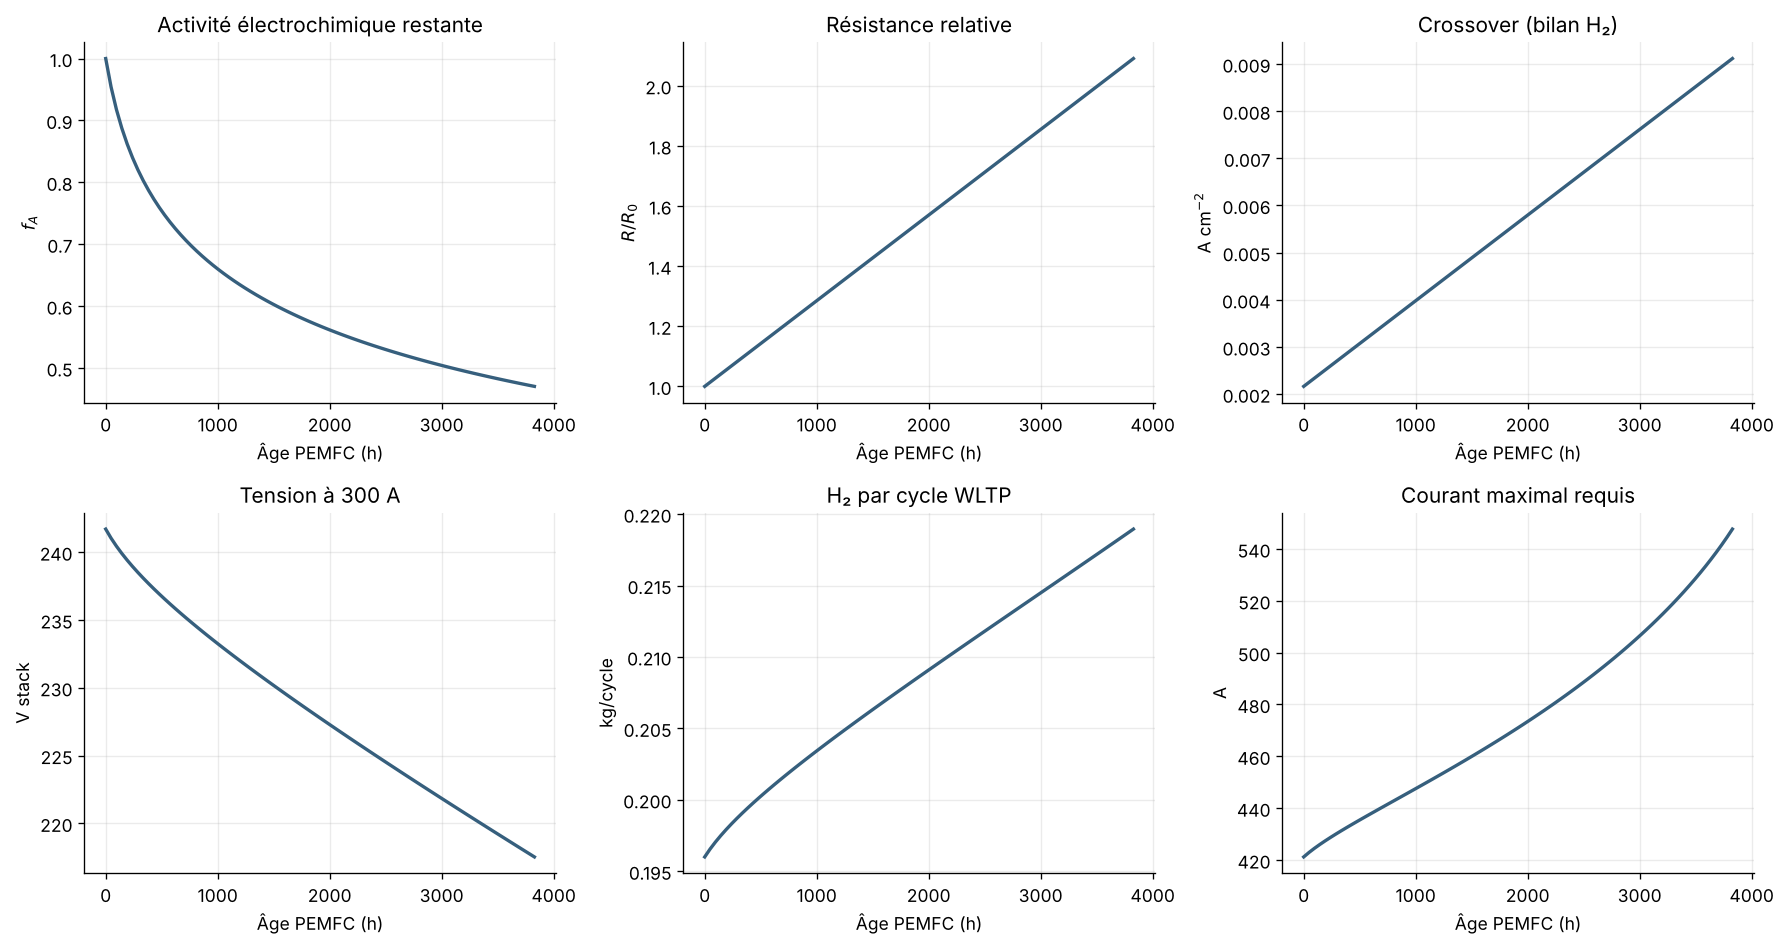

,Age_h,fA,Rratio,icross,U300,H2,Imax,feasible
0,0.00000,1.00000,1.00000,0.00217,241.69825,0.19600,421.20000,1.0
40,1913.94837,0.56774,1.54535,0.00564,227.77075,0.20861,471.02310,1.0
80,3827.89673,0.47024,2.09071,0.00912,217.52843,0.21895,547.66386,1.0


In [3]:
life_fc=fc_eol(FC_CENTRAL);ages_fc=np.linspace(0,life_fc,81)
fc_curve=pd.DataFrame([{"Age_h":a,**fc_state(a,FC_CENTRAL)} for a in ages_fc])
fig,axs=plt.subplots(2,3,figsize=(15,8))
spec=[("fA","Activité électrochimique restante","$f_A$"),("Rratio","Résistance relative","$R/R_0$"),
      ("icross","Crossover (bilan H₂)","A cm$^{-2}$"),("U300","Tension à 300 A","V stack"),
      ("H2","H₂ par cycle WLTP","kg/cycle"),("Imax","Courant maximal requis","A")]
for ax,(c,t,y) in zip(axs.flat,spec):ax.plot(fc_curve.Age_h,fc_curve[c],color="#365F7D",lw=2);ax.set(title=t,xlabel="Âge PEMFC (h)",ylabel=y)
fig.tight_layout();fig.savefig(OUT/"PEMFC_01_mecanismes.png",dpi=220);plt.show()
display(fc_curve.iloc[[0,40,80]].round(5))


## 4. Sensibilité locale PEMFC

Chaque constante varie entre les deux valeurs publiées (cellules B et C de Colombo et al., 2023), les autres restant au cas moyen. Deux lectures :

- **EoL propre** : effet sur la durée de vie ;
- **âge commun de 2000 h** : consommation après la même durée d'exposition.

La fin de vie est fixée par la perte de 10 % de tension (DOE) ; le critère de membrane n'est testé qu'en sensibilité. Le seuil de tension (5, 10, 15 %) est un choix de définition : il est présenté comme scénario, pas comme incertitude.

,Paramètre,Valeur,EoL_h,EoL_tension_h,t_membrane_h,Cause,fA_EOL,Rratio_EOL,H2_EOL,H2_2000h,Hausse_H2_2000h_pct,Imax_2000h
0,omega,3.000000,3767.079016,3767.079016,7159.549098,tension,0.457543,2.073377,0.218903,0.209200,6.734860,473.918387
1,omega,3.600000,3827.896730,3827.896730,7159.549098,tension,0.470237,2.090707,0.218950,0.209087,6.676786,473.445323
2,omega,4.000000,3864.290998,3864.290998,7159.549098,tension,0.478000,2.101077,0.218979,0.209019,6.642431,473.165912
3,k_R,0.000171,5878.238941,5878.238941,7159.549098,tension,0.412327,2.007483,0.225872,0.208016,6.130605,456.002208
4,k_R,0.000285,3827.896730,3827.896730,7159.549098,tension,0.470237,2.090707,0.218950,0.209087,6.676786,473.445323
5,k_R,0.000398,2867.545105,2867.545105,7159.549098,tension,0.510443,2.142661,0.215609,0.210221,7.255393,495.109126
6,k_mem,0.000336,3827.896730,3827.896730,16250.000000,tension,0.470237,2.090707,0.212417,0.205673,4.935359,473.445323
7,k_mem,0.000646,3827.896730,3827.896730,7159.549098,tension,0.470237,2.090707,0.218950,0.209087,6.676786,473.445323
8,k_mem,0.000956,3827.896730,3827.896730,4062.500000,tension,0.470237,2.090707,0.227853,0.213738,9.049950,473.445323
9,S1000,0.650000,3788.162389,3788.162389,7159.549098,tension,0.461904,2.079385,0.218919,0.209235,6.752782,474.064565


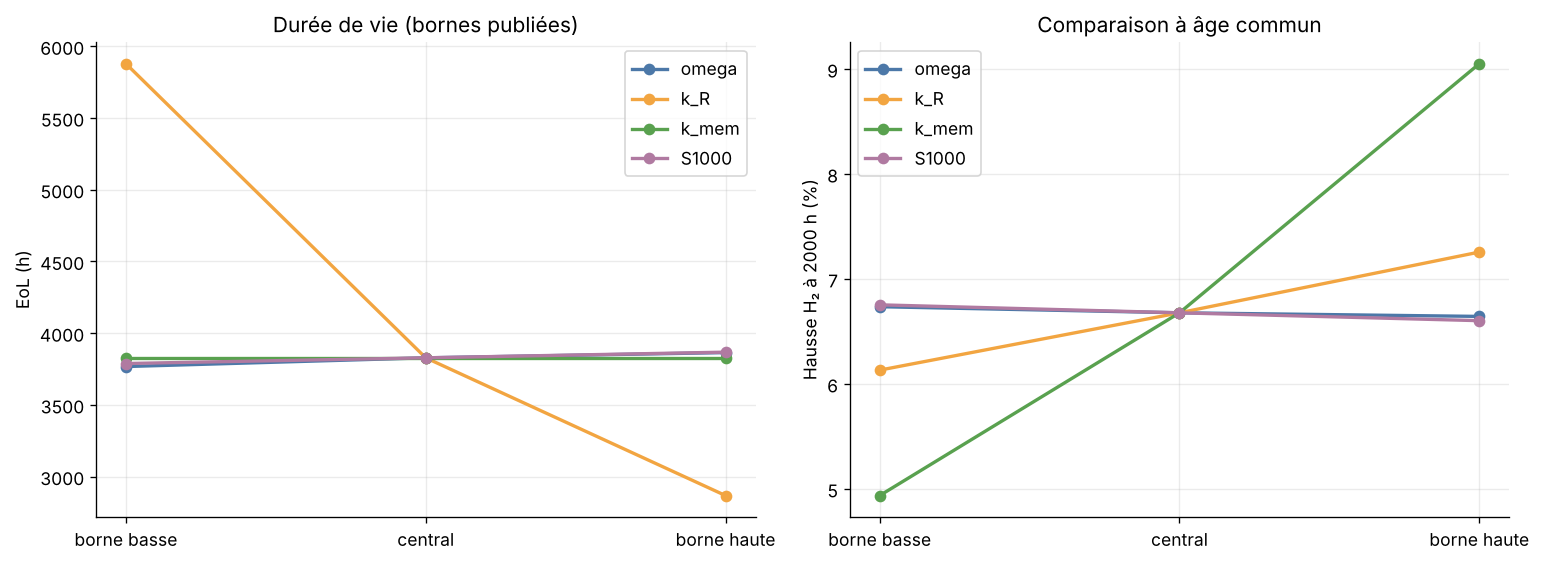

In [4]:
FC_TESTS={k:[FC_BOUNDS[k][0],FC_CENTRAL[k],FC_BOUNDS[k][1]] for k in ["omega","k_R","k_mem","S1000"]}
FC_TESTS["eol_frac"]=[.05,.10,.15];AGE_FC=2000.
rows=[]
for par,vals in FC_TESTS.items():
 for val in vals:
  p=FC_CENTRAL.copy();p[par]=val;life=fc_eol(p);qe=fc_state(life,p);qc=fc_state(AGE_FC,p)
  rows.append({"Paramètre":par,"Valeur":val,"EoL_h":life,"EoL_tension_h":fc_eol_tension(p),"t_membrane_h":fc_t_membrane(p),"Cause":fc_eol_cause(p),"fA_EOL":qe["fA"],"Rratio_EOL":qe["Rratio"],
   "H2_EOL":qe["H2"],"H2_2000h":qc["H2"],"Hausse_H2_2000h_pct":pct(qc["H2"],FC_H2EXP0),"Imax_2000h":qc["Imax"]})
fc_sens=pd.DataFrame(rows);display(fc_sens.round(6))
fig,axs=plt.subplots(1,2,figsize=(13,4.8))
for par,c in [("omega","#4C78A8"),("k_R","#F2A541"),("k_mem","#59A14F"),("S1000","#B07AA1")]:
 q=fc_sens[fc_sens["Paramètre"]==par];x=["borne basse","central","borne haute"]
 axs[0].plot(x,q.EoL_h,"o-",lw=2,label=par,color=c);axs[1].plot(x,q.Hausse_H2_2000h_pct,"o-",lw=2,label=par,color=c)
axs[0].set(ylabel="EoL (h)",title="Durée de vie (bornes publiées)")
axs[1].set(ylabel="Hausse H₂ à 2000 h (%)",title="Comparaison à âge commun")
for ax in axs:ax.legend()
fig.tight_layout();fig.savefig(OUT/"PEMFC_02_sensibilite.png",dpi=220);plt.show()

## 5. Monte-Carlo PEMFC

$\omega$ (3 à 4, Verducci et al.), $S(1000\,\mathrm{h})$ (0,65 à 0,67), $k_R$ et $k_{mem}$ (cellules B et C de Colombo et al.) suivent des lois uniformes entre les bornes publiées. Le critère EoL reste fixé à 10 %. Les percentiles décrivent la dispersion due à l'écart entre les données publiées, pas un intervalle de confiance expérimental.

Le coefficient de Spearman mesure une association monotone entre une entrée et une sortie. Il ne prouve pas une causalité.

,Analyse,Sortie,P5,Médiane,P95
0,PEMFC,EoL_h,2923.6887,3823.3238,5473.2631
1,PEMFC,EoL_tension_h,2923.6887,3823.3238,5473.2631
2,PEMFC,t_membrane_h,4274.8044,7202.1774,14723.0882
3,PEMFC,Hausse_H2_2000h_pct,5.0205,6.6621,8.8874


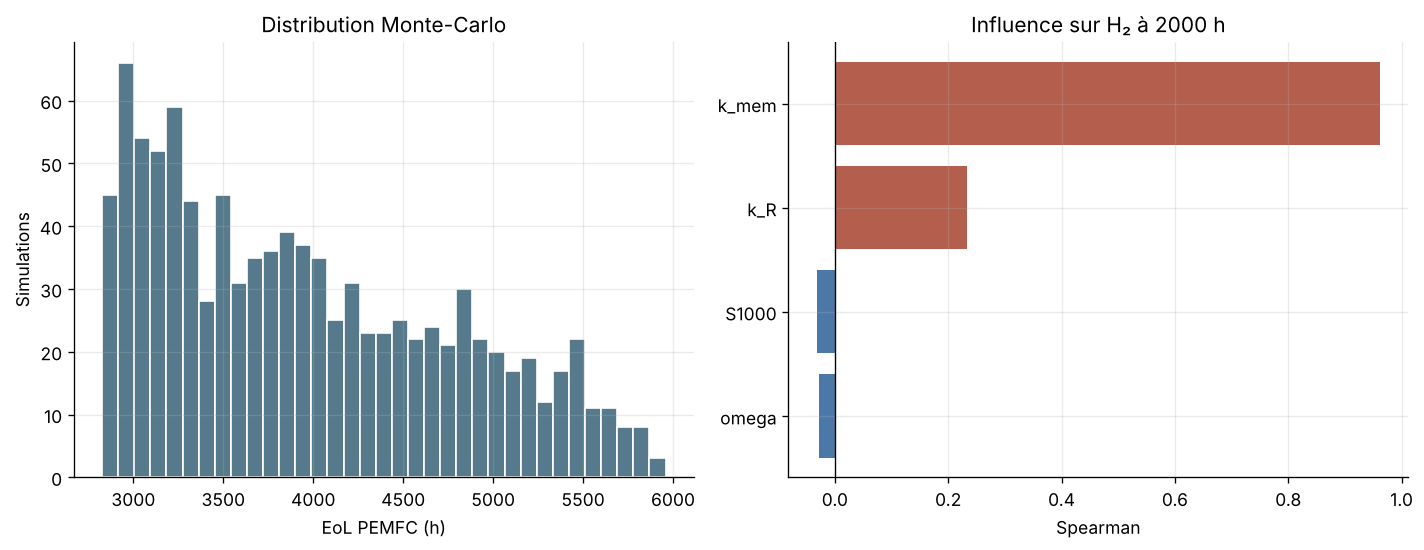

In [5]:
rng=np.random.default_rng(42)
fc_in=pd.DataFrame({k:rng.uniform(*FC_BOUNDS[k],N_MC) for k in ["omega","k_R","k_mem","S1000"]})
out=[]
for _,r0 in fc_in.iterrows():
 p=FC_CENTRAL.copy();p.update(r0.to_dict());life=fc_eol(p);q=fc_state(AGE_FC,p)
 out.append({"EoL_h":life,"EoL_tension_h":fc_eol_tension(p),"t_membrane_h":fc_t_membrane(p),"H2_2000h":q["H2"],"Hausse_H2_2000h_pct":pct(q["H2"],FC_H2EXP0)})
fc_mc=pd.concat([fc_in,pd.DataFrame(out)],axis=1);fc_mc_sum=percentiles(fc_mc,["EoL_h","EoL_tension_h","t_membrane_h","Hausse_H2_2000h_pct"],"PEMFC")
display(fc_mc_sum.round(4))
fc_rho=pd.DataFrame([{"Entrée":x,"Sortie":y,"Rho":spearmanr(fc_mc[x],fc_mc[y],nan_policy="omit").statistic} for x in fc_in for y in ["EoL_h","Hausse_H2_2000h_pct"]])
fig,axs=plt.subplots(1,2,figsize=(12,4.7));axs[0].hist(fc_mc.EoL_h,bins=35,color="#567A8C",edgecolor="white")
q=fc_rho[fc_rho.Sortie=="Hausse_H2_2000h_pct"].sort_values("Rho",key=abs);axs[1].barh(q.Entrée,q.Rho,color=np.where(q.Rho>=0,"#B45F4D","#4C78A8"));axs[1].axvline(0,color="black",lw=.8)
axs[0].set(xlabel="EoL PEMFC (h)",ylabel="Simulations",title="Distribution Monte-Carlo");axs[1].set(xlabel="Spearman",title="Influence sur H₂ à 2000 h")
fig.tight_layout();fig.savefig(OUT/"PEMFC_03_MonteCarlo.png",dpi=220);plt.show()

# Partie II — PEMWE seul

## 6. Modèle électrique et faradique

$$f_A(t)=f_{A,min}+(1-f_{A,min})e^{-k_{cat}t},\qquad R_{tot}(t)=R_0+\frac{dR}{dt}\,t,\qquad \eta_F(t)=1-\frac{1-\eta_{F,0}}{e(t)/e_0},\quad \frac{e(t)}{e_0}=1-\frac{t}{2\,t_{50}},$$

$$SEC(t)=\frac{E(t)}{m_{H_2}(t)}.$$

**Constantes issues de la littérature.**

| Grandeur | Optimiste | Moyen | Pessimiste | Source |
|---|---|---|---|---|
| $f_{A,min}$ ; $1/k_{cat}$ | 0,49 ; 1,1 kh (surface active seule) | 0,30 ; 1,05 kh (milieu) | 0,112 ; 1,0 kh (activité massique) | Padgett et al. (2025) |
| Conversion en tension | $-b\log_{10}f_A$, $b=46$ mV/déc | idem | idem | Padgett et al. (2025), éq. 4 |
| $dR/dt$ (mΩ·cm²/kh) | 2,33 (HFR) | 2,90 (HFR + ½ CLR) | 3,47 (HFR + CLR) | Padgett et al. (2025) |
| $t_{50}$ membrane (h) | 110 100 | 95 400 | 80 700 | Chandesris et al. (2015), 353 K (80 °C) |

**Hypothèses (empilement commercial : Ti revêtu, IrO₂, membrane épaisse, $\bar j$ = 1,2 A/cm², 80 °C).**
- Température de 80 °C : celle des essais de Padgett et de la valeur à 353 K de Chandesris ; elle n'est pas identifiable par le fitting. 60 °C est testé en sensibilité pour la membrane.
- La perte cinétique est transposée en tension avec la pente de Tafel mesurée par Padgett (46 mV/déc), car c'est la perte de tension qui est mesurée ; la pente du modèle (70 mV/déc à 80 °C) majorerait cette perte de 52 %.
- La croissance de HFR mesurée à 3 A/cm² est conservée dans tous les scénarios, bien que Padgett ne l'observe pas à 1,5 A/cm² : hypothèse prudente.
- La croissance de la résistance de couche catalytique est liée à la dissolution d'Ir (29 % à 0,4 mgIr/cm² contre 5 % à 1,1 mgIr/cm²) ; sa part retenue varie de 0 à 1 entre scénarios.
- Les cas Ti non revêtu (Papakonstantinou) et Rakousky (2 A/cm², 80 °C) sont des cas de stress, traités uniquement en sensibilité.
- Validation, sans calage : les taux moyens équivalents (3,0 / 4,0 / 5,5 µV/h) encadrent l'état DOE 2022 (4,8 µV/h, 40 000 h) et sont proches de la cible 2026 (2,3 µV/h, 80 000 h) et de Siracusano (≈ 5 µV/h à 1,6 mg/cm²).

Le rendement faradique suit l'amincissement de la membrane : le crossover est supposé inversement proportionnel à l'épaisseur.

**Fin de vie (DOE)** : hausse de 10 % de la tension au courant de référence $j_{ref}=1{,}2$ A/cm² (courant moyen du profil), $V(j_{ref},t_{EoL})=1{,}10\,V(j_{ref},0)$ avec $V(j_{ref},0)=1{,}8586$ V. C'est la même règle que pour la pile (tension à 300 A).

La formulation agrégée utilisée ci-dessous est algébriquement exacte pour ce profil de courant fixe.

In [6]:
# ---------------------------------------------------------------- état neuf du PEMWE
# Lu dans pemwe_parametres.json, écrit par le notebook AB_vieillissement_PEMWE (exécuter celui-ci d'abord).
# Cinétique : alpha_a issu de la pente de Tafel mesurée (46 mV/déc, Padgett et al. 2025) ; cathode négligée ; E_rev(T).
import json as _json
from pathlib import Path as _Path
_PJ=next((p for p in [_Path("pemwe_parametres.json"),_Path("resultats_PEMWE_temperature_vieillissement")/"pemwe_parametres.json"] if p.exists()),None)
if _PJ is None: raise FileNotFoundError("pemwe_parametres.json introuvable : exécuter d'abord AB_vieillissement_PEMWE et placer le fichier à côté de ce notebook.")
PEMWE_P=_json.load(open(_PJ,encoding="utf-8"))
WE_T=PEMWE_P["T_K"];WE_R0=PEMWE_P["R0"];WE_ETAF0=PEMWE_P["etaF0"]
WE_E0=PEMWE_P["E0"];WE_H20=PEMWE_P["H20"];WE_SEC0=WE_E0/WE_H20;WE_V0=PEMWE_P["Vmean0"]
# Fin de vie (DOE) : +10 % de tension au courant de référence, le courant moyen du profil (j_ref).
WE_VREF0=PEMWE_P["Vref0"]
WE_W0=PEMWE_P["W0"];WE_WJ=PEMWE_P["Wj"];WE_JMEAN=PEMWE_P["j_ref"]
# Conversion activité -> tension : pente de Tafel mesurée par Padgett et al. (2025), identique à celle du modèle neuf.
WE_BTAF=PEMWE_P["b_tafel"];WE_CDEG=WE_BTAF/np.log(10)
print(f"PEMWE (fichier {_PJ}) : R0={1e3*WE_R0:.1f} mOhm.cm2 ; V_ref(0)={WE_VREF0:.4f} V ; SEC0={WE_SEC0:.3f} kWh/kg")

# ---------------------------------------------------------------- constantes issues de la littérature
# Padgett et al., J. Electrochem. Soc. 172 (2025) 054508 — 4000 h à 3 A/cm², 80 °C, 0,4 mgIr/cm² :
#   activité massique (IrO2 amorphe qui cristallise) : plateau 10,4/93, temps 1,0 kh ;
#   capacité (proxy de la surface active seule) : plateau 0,49, temps 1,1 kh ;
#   HFR : 7 µV/h à 3 A/cm² ; couche catalytique (CLR) : 3,4 µV/h à 3 A/cm² (liée à la dissolution d'Ir).
PADGETT={"fA_masse":10.4/93,"k_masse":1/1000.,"fA_capa":.49,"k_capa":1/1100.,"dHFR":7e-6/3.0,"dCLR":3.4e-6/3.0}
# Cas de stress (sensibilité seulement, non représentatifs d'un empilement commercial) :
RAKOUSKY_R=12e-6/2.0   # Rakousky et al. 2016 : 12 µV/h à 2 A/cm², 80 °C (toute la dérive attribuée à R)
PAPA_R=43.5e-6         # Papakonstantinou et al. 2020 : 43,5 µΩ.cm²/h, 60 °C, Ti non revêtu (cas de stress)
# Chandesris et al., Int. J. Hydrogen Energy 40 (2015) 1353 : 50 % d'amincissement à 353 K (80 °C) en 110 100 h (modèle linéaire)
#   et 80 700 h (modèle couplé) ; à 333 K (60 °C) : 590 500 h et 380 500 h (sensibilité).
CHANDESRIS_T50={"lineaire":110100.,"couple":80700.}
CHANDESRIS_T50_60C={"lineaire":590500.,"couple":380500.}
# Points de validation (non utilisés pour caler) : DOE 2022 4,8 µV/h (40 000 h) ; DOE 2026 2,3 µV/h (80 000 h) ;
#   Siracusano et al. (cité par Maoulida et al. 2026) : ~5 µV/h à 1,6 mg/cm², ~15 µV/h à 0,5 mg/cm².
WE_VALID={"DOE 2026 (cible)":2.3,"DOE 2022 (état)":4.8,"Siracusano, 1,6 mg/cm²":5.0,"Siracusano, 0,5 mg/cm²":15.0}

def we_params(fA_min,k_cat,r,t50):
    return {"fA_min":fA_min,"k_cat":k_cat,"k_R":r/WE_R0,"t50_mem":t50,"eol_frac":.10}
_mid=lambda a,b:.5*(a+b)
# V18 : seul le jeu « Pessimiste » est utilisé dans l'étude (cas pessimiste) ; « Optimiste » et « Moyen » sont gardés pour mémoire.
WE_SCEN={"Optimiste":we_params(PADGETT["fA_capa"],PADGETT["k_capa"],PADGETT["dHFR"],CHANDESRIS_T50["lineaire"]),
         "Moyen":we_params(_mid(PADGETT["fA_capa"],PADGETT["fA_masse"]),_mid(PADGETT["k_capa"],PADGETT["k_masse"]),
                           PADGETT["dHFR"]+.5*PADGETT["dCLR"],_mid(CHANDESRIS_T50["couple"],CHANDESRIS_T50["lineaire"])),
         "Pessimiste":we_params(PADGETT["fA_masse"],PADGETT["k_masse"],PADGETT["dHFR"]+PADGETT["dCLR"],CHANDESRIS_T50["couple"])}
WE_CENTRAL=WE_SCEN["Moyen"]

def we_state(t,p):
 t=np.asarray(t,float);fa=p["fA_min"]+(1-p["fA_min"])*np.exp(-p["k_cat"]*t)
 # crossover proportionnel à 1/épaisseur ; épaisseur e/e0 = 1 - 0,5 t/t50 (Chandesris et al., 2015)
 eta=1-(1-WE_ETAF0)/(1-0.5*t/p["t50_mem"])
 dv=p.get('b',WE_BTAF)/np.log(10)*(-np.log(fa));vm=WE_V0+dv+WE_R0*p["k_R"]*t*WE_JMEAN
 en=WE_E0+dv*WE_W0+WE_R0*p["k_R"]*t*WE_WJ;h=WE_H20*eta/WE_ETAF0
 return {"fA":fa,"Rratio":1+p["k_R"]*t,"etaF":eta,"Vmean":vm,"Vref":WE_VREF0+(vm-WE_V0),"Energy":en,"H2":h,"SEC":en/h}
def we_eol(p,maxh=400000):
 # tension au courant de référence j_ref = WE_JMEAN : V_ref(t) = V_ref(0) + ΔV_cin + R0 k_R t j_ref
 g=lambda t:float(we_state(t,p)["Vref"]-(1+p["eol_frac"])*WE_VREF0)
 return brentq(g,0,maxh) if g(maxh)>=0 else np.nan
display(pd.DataFrame({n:{"f_A,min":p["fA_min"],"k_cat (1/h)":p["k_cat"],"dR/dt (mOhm.cm²/kh)":1e6*p["k_R"]*WE_R0,
  "k_R (1/h)":p["k_R"],"t50 membrane (h)":p["t50_mem"],"EoL (h)":we_eol(p)} for n,p in WE_SCEN.items()}).T)
print(f"PEMWE central : EoL={we_eol(WE_CENTRAL):.1f} h ; SEC0={WE_SEC0:.4f} kWh/kg")
print("Taux moyens équivalents (µV/h) = 10 % V_ref / EoL :",{n:round(1e6*.10*WE_VREF0/we_eol(p),2) for n,p in WE_SCEN.items()},"— références :",WE_VALID)

PEMWE (fichier pemwe_parametres.json) : R0=215.5 mOhm.cm2 ; V_ref(0)=1.8600 V ; SEC0=53.676 kWh/kg


,"f_A,min",k_cat (1/h),dR/dt (mOhm.cm²/kh),k_R (1/h),t50 membrane (h),EoL (h)
Optimiste,0.490000,0.000909,2.333333,0.000011,110100.0,61311.455642
Moyen,0.300914,0.000955,2.900000,0.000013,95400.0,46533.275923
Pessimiste,0.111828,0.001000,3.466667,0.000016,80700.0,34175.406934


PEMWE central : EoL=46533.3 h ; SEC0=53.6756 kWh/kg
Taux moyens équivalents (µV/h) = 10 % V_ref / EoL : {'Optimiste': 3.03, 'Moyen': 4.0, 'Pessimiste': 5.44} — références : {'DOE 2026 (cible)': 2.3, 'DOE 2022 (état)': 4.8, 'Siracusano, 1,6 mg/cm²': 5.0, 'Siracusano, 0,5 mg/cm²': 15.0}


## 7. Courbes des mécanismes PEMWE

Les figures distinguent la dégradation de l'électrode, l'augmentation de résistance et la perte faradique. Cela permet de vérifier que la hausse de SEC n'est pas une courbe imposée : elle résulte de l'énergie et de la production nette calculées.


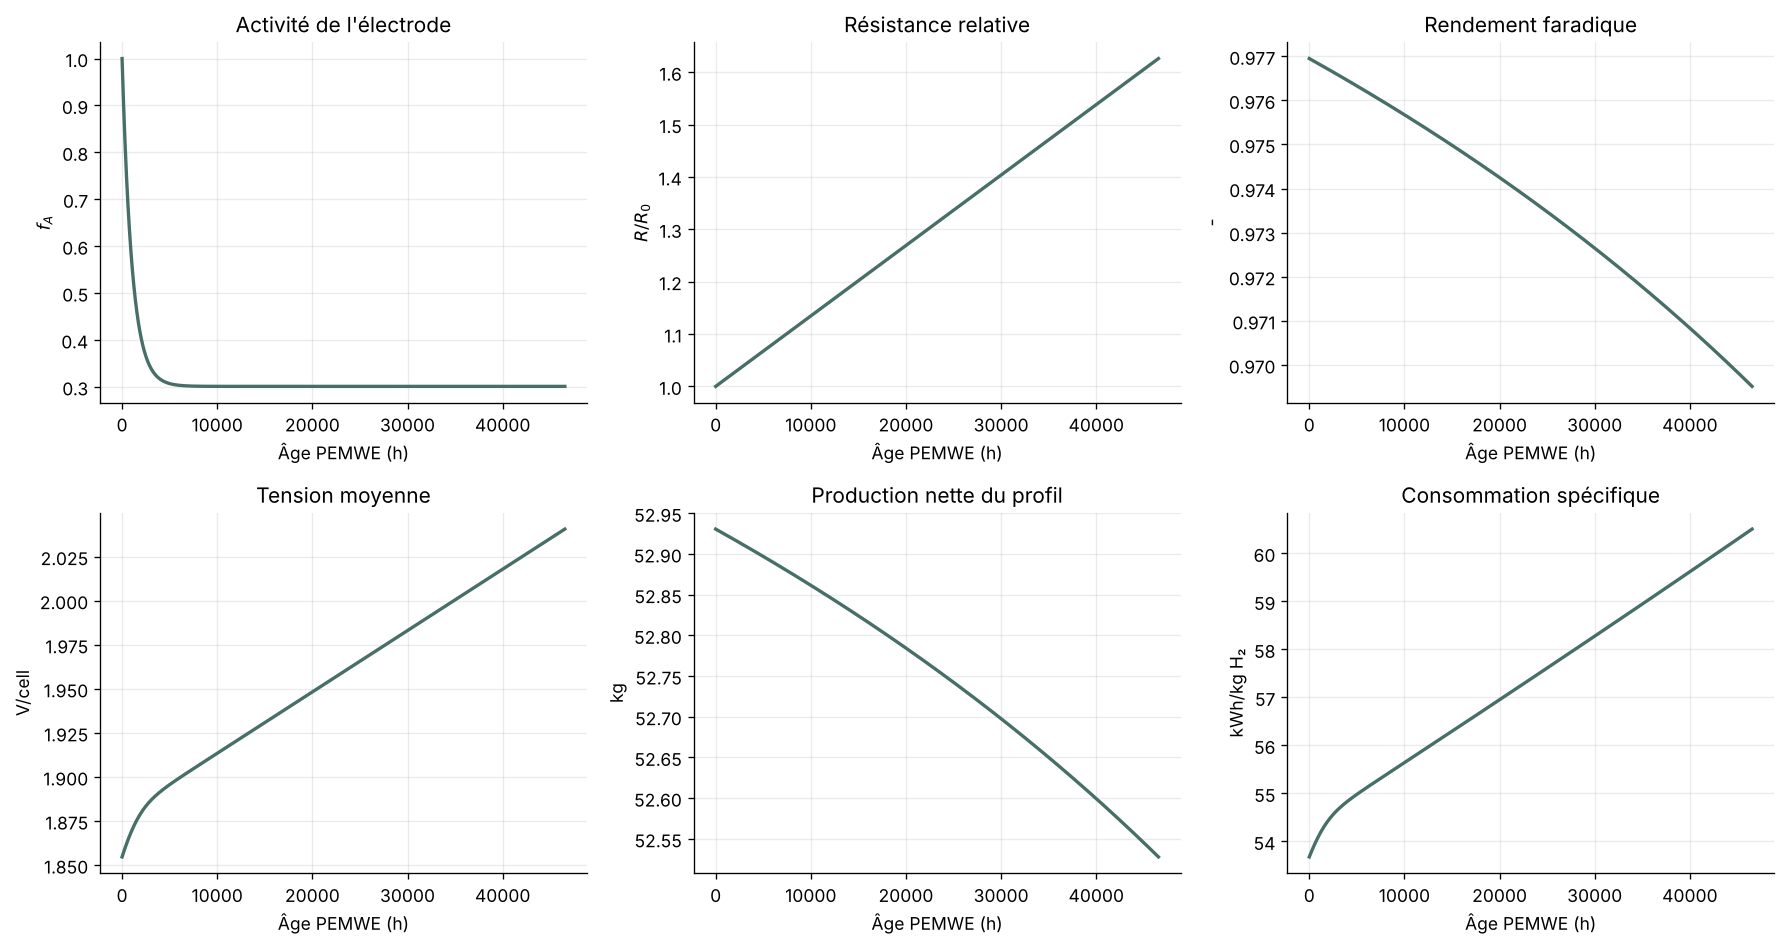

,Age_h,fA,Rratio,etaF,Vmean,Vref,Energy,H2,SEC
0,0.00000,1.00000,1.00000,0.97695,1.85462,1.86001,2841.08000,52.93052,53.67564
150,23266.63796,0.30091,1.31303,0.97375,1.95961,1.96500,3027.26722,52.75708,57.38125
300,46533.27592,0.30091,1.62606,0.96951,2.04062,2.04601,3178.18615,52.52769,60.50497


In [7]:
life_we=we_eol(WE_CENTRAL);ages_we=np.linspace(0,life_we,301);qw=we_state(ages_we,WE_CENTRAL)
we_curve=pd.DataFrame({"Age_h":ages_we,**qw})
fig,axs=plt.subplots(2,3,figsize=(15,8))
spec=[("fA","Activité de l'électrode","$f_A$"),("Rratio","Résistance relative","$R/R_0$"),("etaF","Rendement faradique","-"),
      ("Vmean","Tension moyenne","V/cell"),("H2","Production nette du profil","kg"),("SEC","Consommation spécifique","kWh/kg H₂")]
for ax,(c,t,y) in zip(axs.flat,spec):ax.plot(we_curve.Age_h,we_curve[c],color="#476F68",lw=2);ax.set(title=t,xlabel="Âge PEMWE (h)",ylabel=y)
fig.tight_layout();fig.savefig(OUT/"PEMWE_01_mecanismes.png",dpi=220);plt.show()
display(we_curve.iloc[[0,150,300]].round(5))


## 8. Sensibilité locale PEMWE

L'âge commun est fixé à 15 000 h, inférieur à toutes les fins de vie. Chaque cas remplace une constante du cas moyen par une autre valeur publiée.

,Paramètre,Cas,EoL_h,SEC_EOL,etaF_EOL,SEC_15000h,Hausse_SEC_15000h_pct
0,dR/dt,"Padgett, HFR seule",57834.2144,60.6671,0.9669,55.9336,4.2066
1,dR/dt,"Padgett, HFR + ½ CLR (central)",46533.2759,60.5050,0.9695,56.2935,4.8772
2,dR/dt,"Padgett, HFR + CLR",38926.8751,60.4098,0.9710,56.6534,5.5477
3,dR/dt,"stress : Rakousky, 2 A/cm²",22491.0834,60.2344,0.9739,58.2624,8.5454
4,dR/dt,stress : Ti non revêtu,3144.0429,60.0845,0.9766,82.0804,52.9192
5,dR/dt,"nulle (Padgett à 1,5 A/cm²)",NaN,NaN,NaN,54.4516,1.4456
6,f_A,"capacité (0,49 ; 1,1 kh)",49331.0563,60.6156,0.9689,56.0224,4.3722
7,f_A,"pente de Tafel 43,3 mV/déc",46937.7501,60.5209,0.9694,56.2543,4.8042
8,f_A,pente de Tafel 49 mV/déc,46083.8602,60.4874,0.9696,56.3370,4.9583
9,f_A,"activité massique (0,112 ; 1,0 kh)",40853.3600,60.2852,0.9707,56.8438,5.9024


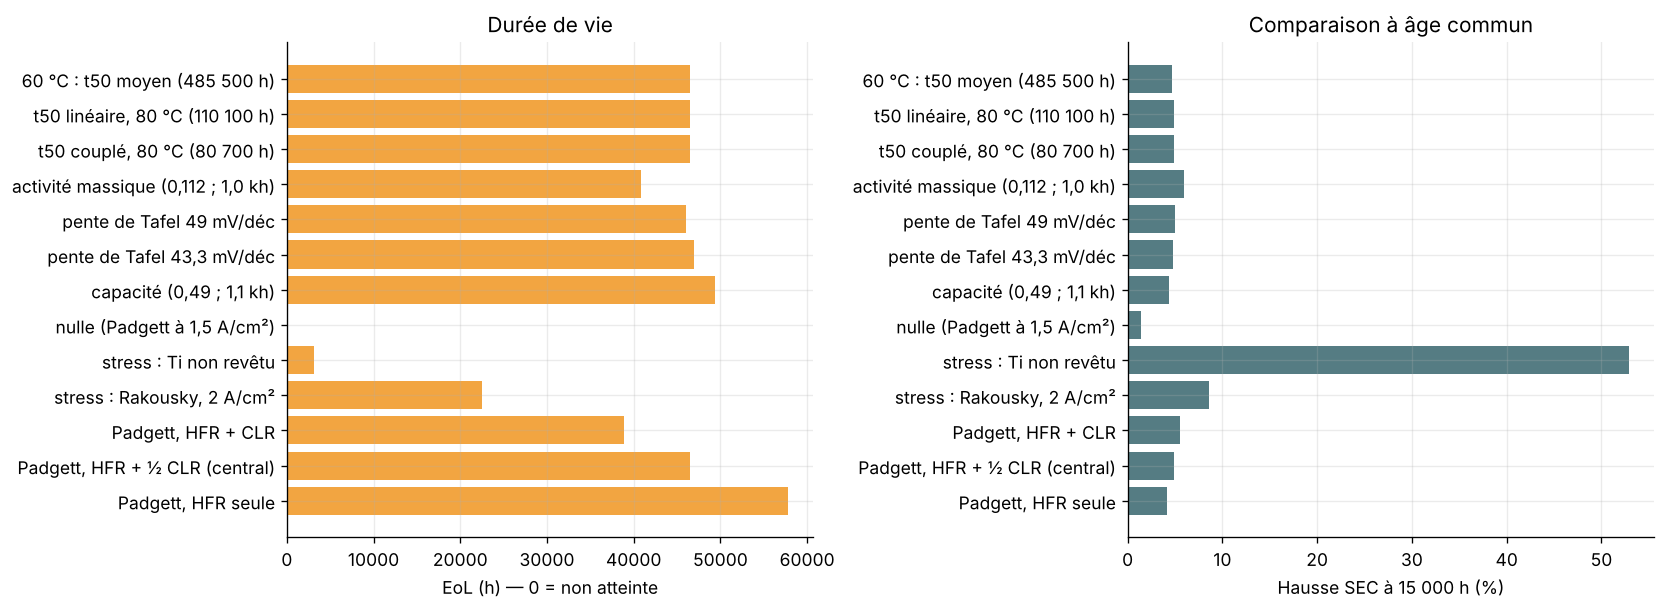

In [8]:
AGE_WE=15000.
WE_CASES=[("dR/dt","Padgett, HFR seule",{"k_R":PADGETT["dHFR"]/WE_R0}),
          ("dR/dt","Padgett, HFR + ½ CLR (central)",{"k_R":(PADGETT["dHFR"]+.5*PADGETT["dCLR"])/WE_R0}),
          ("dR/dt","Padgett, HFR + CLR",{"k_R":(PADGETT["dHFR"]+PADGETT["dCLR"])/WE_R0}),
          ("dR/dt","stress : Rakousky, 2 A/cm²",{"k_R":RAKOUSKY_R/WE_R0}),
          ("dR/dt","stress : Ti non revêtu",{"k_R":PAPA_R/WE_R0}),
          ("dR/dt","nulle (Padgett à 1,5 A/cm²)",{"k_R":0.}),
          ("f_A","capacité (0,49 ; 1,1 kh)",{"fA_min":PADGETT["fA_capa"],"k_cat":PADGETT["k_capa"]}),
          ("f_A","pente de Tafel 43,3 mV/déc",{"b":0.0433}),
          ("f_A","pente de Tafel 49 mV/déc",{"b":0.049}),
          ("f_A","activité massique (0,112 ; 1,0 kh)",{"fA_min":PADGETT["fA_masse"],"k_cat":PADGETT["k_masse"]}),
          ("membrane","t50 couplé, 80 °C (80 700 h)",{"t50_mem":CHANDESRIS_T50["couple"]}),
          ("membrane","t50 linéaire, 80 °C (110 100 h)",{"t50_mem":CHANDESRIS_T50["lineaire"]}),
          ("membrane","60 °C : t50 moyen (485 500 h)",{"t50_mem":.5*(CHANDESRIS_T50_60C["couple"]+CHANDESRIS_T50_60C["lineaire"])}),
          ("seuil EoL","5 %",{"eol_frac":.05}),("seuil EoL","15 %",{"eol_frac":.15})]
rows=[]
for grp,cas,upd in WE_CASES:
 p=WE_CENTRAL.copy();p.update(upd)
 life=we_eol(p);qc=we_state(AGE_WE,p)
 qe=we_state(life,p) if np.isfinite(life) else {k:np.nan for k in ["SEC","etaF"]}
 rows.append({"Paramètre":grp,"Cas":cas,"EoL_h":life,"SEC_EOL":float(qe["SEC"]),"etaF_EOL":float(qe["etaF"]),
              "SEC_15000h":float(qc["SEC"]),"Hausse_SEC_15000h_pct":pct(qc["SEC"],WE_SEC0)})
we_sens=pd.DataFrame(rows);display(we_sens.round(4))
fig,axs=plt.subplots(1,2,figsize=(14,5.2))
q=we_sens[we_sens.Paramètre!="seuil EoL"]
axs[0].barh(q.Cas,q.EoL_h.fillna(0),color="#F2A541");axs[0].set(xlabel="EoL (h) — 0 = non atteinte",title="Durée de vie")
axs[1].barh(q.Cas,q.Hausse_SEC_15000h_pct,color="#557C83");axs[1].set(xlabel="Hausse SEC à 15 000 h (%)",title="Comparaison à âge commun")
fig.tight_layout();fig.savefig(OUT/"PEMWE_02_sensibilite.png",dpi=220,bbox_inches="tight");plt.show()

## 9. Monte-Carlo PEMWE

Lois uniformes entre les valeurs publiées de Padgett et al. (2025) et Chandesris et al. (2015) : $f_{A,min}\in[0{,}112;0{,}49]$, $1/k_{cat}\in[1{,}0;1{,}1]$ kh, $dR/dt\in[2{,}33;3{,}47]$ mΩ·cm²/kh (HFR seule à HFR + CLR), $t_{50}\in[380\,500;590\,500]$ h. Les cas de stress (Ti non revêtu, Rakousky) sont traités en sensibilité. Sorties : durée de vie et SEC à 15 000 h.

,Analyse,Sortie,P5,Médiane,P95
0,PEMWE,EoL_h,38150.5364,46485.4873,57381.7966
1,PEMWE,SEC_15000h,55.8346,56.3185,56.8715


,Entrée,Sortie,Rho
0,fA_min,EoL_h,0.364
1,fA_min,SEC_15000h,-0.700
2,k_cat,EoL_h,-0.029
3,k_cat,SEC_15000h,0.029
4,k_R,EoL_h,-0.920
5,k_R,SEC_15000h,0.680
6,t50_mem,EoL_h,-0.009
7,t50_mem,SEC_15000h,-0.012


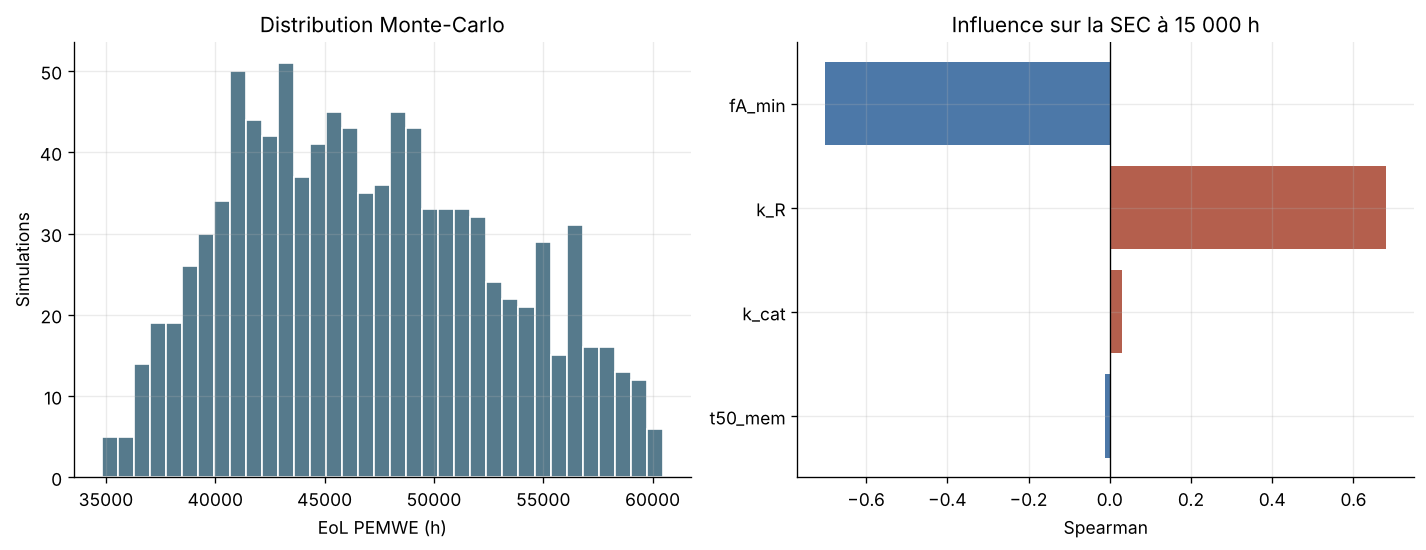

In [9]:
rng=np.random.default_rng(43)
we_in=pd.DataFrame({"fA_min":rng.uniform(PADGETT["fA_masse"],PADGETT["fA_capa"],N_MC),
                    "k_cat":rng.uniform(PADGETT["k_capa"],PADGETT["k_masse"],N_MC),
                    "k_R":rng.uniform(PADGETT["dHFR"],PADGETT["dHFR"]+PADGETT["dCLR"],N_MC)/WE_R0,
                    "t50_mem":rng.uniform(CHANDESRIS_T50["couple"],CHANDESRIS_T50["lineaire"],N_MC)})
out=[]
for _,r0 in we_in.iterrows():
 p=WE_CENTRAL.copy();p.update(r0.to_dict());life=we_eol(p);q=we_state(AGE_WE,p)
 out.append({"EoL_h":life,"SEC_15000h":float(q["SEC"]),"Hausse_SEC_15000h_pct":pct(q["SEC"],WE_SEC0)})
we_mc=pd.concat([we_in,pd.DataFrame(out)],axis=1);we_mc_sum=percentiles(we_mc,["EoL_h","SEC_15000h"],"PEMWE");display(we_mc_sum.round(4))
we_rho=pd.DataFrame([{"Entrée":x,"Sortie":y,"Rho":spearmanr(we_mc[x],we_mc[y],nan_policy="omit").statistic} for x in we_in for y in ["EoL_h","SEC_15000h"]])
display(we_rho.round(3))
fig,axs=plt.subplots(1,2,figsize=(12,4.7));axs[0].hist(we_mc.EoL_h,bins=35,color="#567A8C",edgecolor="white")
q=we_rho[we_rho.Sortie=="SEC_15000h"].sort_values("Rho",key=abs);axs[1].barh(q.Entrée,q.Rho,color=np.where(q.Rho>=0,"#B45F4D","#4C78A8"));axs[1].axvline(0,color="black",lw=.8)
axs[0].set(xlabel="EoL PEMWE (h)",ylabel="Simulations",title="Distribution Monte-Carlo");axs[1].set(xlabel="Spearman",title="Influence sur la SEC à 15 000 h")
fig.tight_layout();fig.savefig(OUT/"PEMWE_03_MonteCarlo.png",dpi=220);plt.show()

# Partie III — ACV et couplage

## 10. Inventaires EF 3.1

Pour chaque indicateur $k$ :

$$IC_{PEMWE,k}(t)=SEC(t)FE_{elec,k}+IC_{eau,k},$$
$$IC_{kgH_2,k}(t)=\frac{IC_{PEMWE,k}(t)+IC_{comp,k}}{1-L_{H_2}},$$
$$IC_{km,k}=c_{H_2,km}(t_{FC})IC_{kgH_2,k}(t_{WE}).$$

$L_{H_2}$ est la fraction d'hydrogène perdue. Le cas central utilise 0 %, tandis que la sensibilité teste jusqu'à 5 %.


In [10]:
IND=["Acidification","Changement climatique","Écotoxicité totale","Écotoxicité inorganique","Écotoxicité organique","Énergie fossile","Eutrophisation eau douce","Eutrophisation marine","Eutrophisation terrestre","Toxicité humaine totale","Toxicité humaine inorganique","Toxicité humaine organique","Ressources minérales","Ozone","Utilisation de l'eau","Particules",'Usage des terres','Radiations ionisantes',"Formation photochimique d'ozone",'Toxicité humaine non cancérigène']
# V7 : électricité « electricity, medium voltage, residual mix, FR » (ecoinvent 3.11), 79,6 g CO2-éq/kWh ; 1 kg H2 à SEC0 = 53,68 kWh
PEMWE0=pd.Series([0.014080271731083883,4.279518514616187,9.216274764335342,9.018659489438866,0.19761527489647454,751.1485348419133,0.0006020793013419391,0.005360203204265161,0.03607825778601173,1.2622317905119135e-09,5.764367453553225e-10,6.857950451565908e-10,3.5110621382400735e-05,1.2921747933230577e-07,6.915084079752976,2.435753146253289e-07,18.37154927146217,34.21778334049153,0.013218293055706492,4.6241096630620186e-08],index=IND)
EAU=pd.Series([4.3015400209306186e-5,.004733269280060789,.5163586472916831,.5155973630639497,.0007612842277334075,.05653778154903194,2.0440058578679185e-6,4.7512683456755126e-6,4.944502800990178e-5,9.699031513101342e-12,1.8535308388814734e-12,7.84550067421987e-12,1.892943055533071e-7,1.6052450945239224e-9,.008718816055577004,3.4746999298301196e-10,0.019804603536997124,0.00032295113797400286,1.688266617734751e-05,1.4053860329714182e-10],index=IND)
COMP3=pd.Series([.0007845600949876251,.23892317979233288,.4862493677029604,.47524694800089473,.011002419702065676,41.97948620928328,3.3536735194147435e-5,.00029932301444871235,.0020136961307415362,7.000564762886212e-11,3.21141860441632e-11,3.789146158469892e-11,1.9517973486203604e-6,7.132409942174174e-9,.3860055312509987,1.3594313332347568e-8,1.0257023310308786,1.9124573449770381,0.0007378436031262743,2.5766187730964955e-09],index=IND)
FE=(PEMWE0-EAU)/WE_SEC0;GWP="Changement climatique"
DIST=20.32349744662911;DUR=0.5644303275925;HFC_AN=(200000./15.)/DIST*DUR   # 200 000 km sur 15 ans (Toyota, Takahashi et al. 2022)
E_COMP=2.8   # kWh d'électricité par kg comprimé (Magnaval et al. 2026) ; COMP3 = impact de 3 kWh, mis à l'échelle par comp/3
def impactkg(sec,loss=0,comp=E_COMP,cf=1):return (sec*FE*cf+EAU+COMP3*(comp/3))/(1-loss)
print("Climat initial chaîne =",impactkg(WE_SEC0)[GWP],"kg CO2-éq/kg H2 livré")


Climat initial chaîne = 4.502513482422365 kg CO2-éq/kg H2 livré


## 10.1 Impacts du PEMWE seul

L'unité fonctionnelle est $1$ kg de H₂ net produit à la sortie du PEMWE. La compression n'est pas incluse dans ce premier bloc :

$$IC^{WE}_{k,kgH_2}(t)=SEC(t)FE_{elec,k}+IC_{eau,k}.$$

Trois états du scénario moyen sont comparés : neuf, âge commun de 15 000 h et EoL. Les valeurs absolues sont conservées dans le tableau. Le graphique montre les hausses relatives car les 16 catégories ont des unités différentes.


État,EoL,Initial,Âge commun 15 000 h
Indicateur,,,
Acidification,1.586628e-02,1.408027e-02,1.476489e-02
Changement climatique,4.823413e+00,4.279519e+00,4.488007e+00
Eutrophisation eau douce,6.784237e-04,6.020793e-04,6.313441e-04
Eutrophisation marine,6.041594e-03,5.360203e-03,5.621398e-03
Eutrophisation terrestre,4.066232e-02,3.607826e-02,3.783545e-02
Formation photochimique d'ozone,1.489795e-02,1.321829e-02,1.386215e-02
Ozone,1.454540e-07,1.292175e-07,1.354413e-07
Particules,2.745220e-07,2.435753e-07,2.554380e-07
Radiations ionisantes,3.857138e+01,3.421778e+01,3.588663e+01


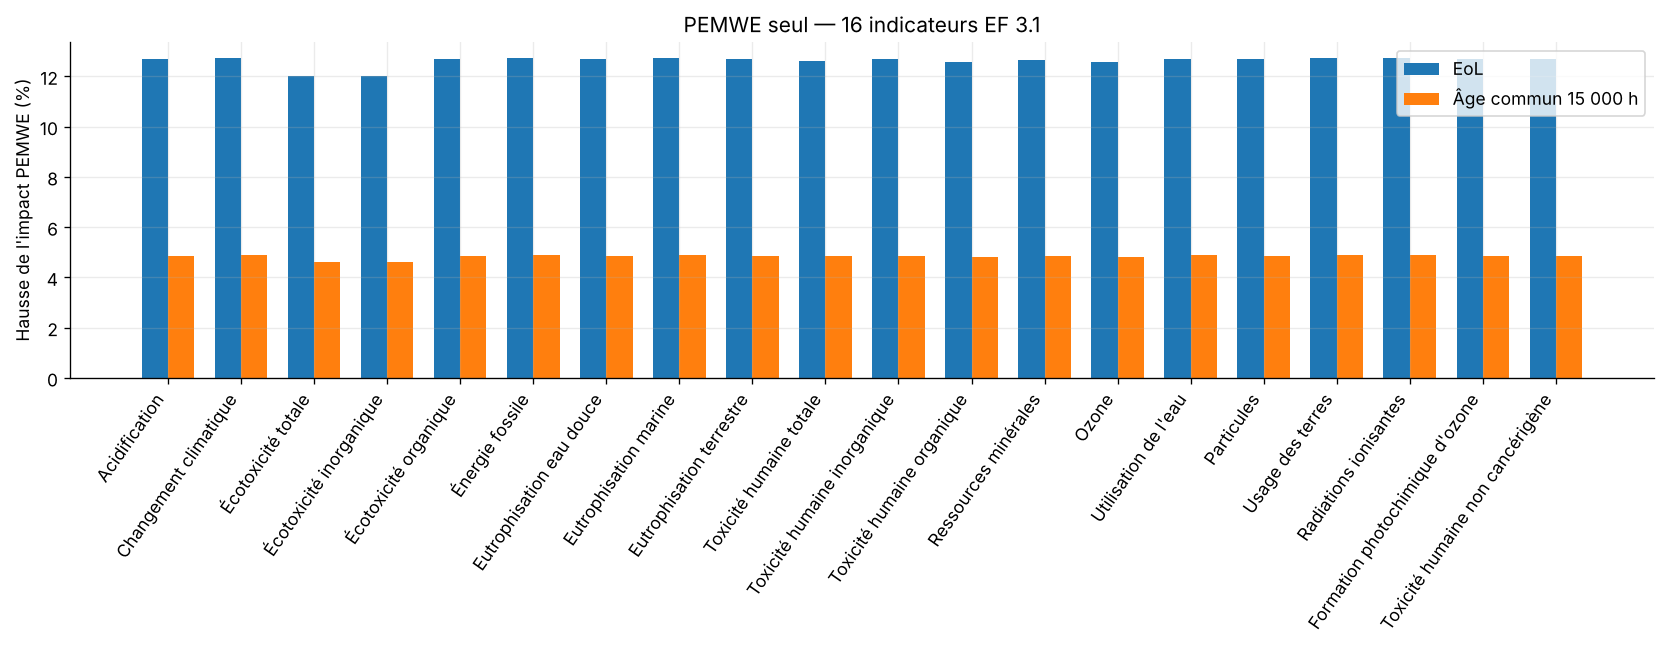

In [11]:
def impact_we_only(sec,cf=1):return float(sec)*FE*cf+EAU
we_ages={"Initial":0.,"Âge commun 15 000 h":AGE_WE,"EoL":we_eol(WE_CENTRAL)}
rows=[];iw0=impact_we_only(WE_SEC0)
for state,age in we_ages.items():
 q=we_state(age,WE_CENTRAL);imp=impact_we_only(q["SEC"])
 for ind in IND:rows.append({"État":state,"Age_PEMWE_h":age,"Indicateur":ind,"Impact_PEMWE_par_kgH2":imp[ind],"Hausse_pct":pct(imp[ind],iw0[ind])})
acv_we=pd.DataFrame(rows);display(acv_we.pivot(index="Indicateur",columns="État",values="Impact_PEMWE_par_kgH2"))
q=acv_we[acv_we.État!="Initial"].pivot(index="Indicateur",columns="État",values="Hausse_pct").loc[IND]
fig,ax=plt.subplots(figsize=(14,5.5));x=np.arange(len(IND));wbar=.36
for n,c in enumerate(q.columns):ax.bar(x+(n-.5)*wbar,q[c],wbar,label=c)
ax.set_xticks(x,IND,rotation=55,ha="right");ax.set_ylabel("Hausse de l'impact PEMWE (%)");ax.set_title("PEMWE seul — 16 indicateurs EF 3.1");ax.legend()
fig.tight_layout();fig.savefig(OUT/"ACV_01_PEMWE_seul.png",dpi=220);plt.show()


## 10.2 Impacts associés à la PEMFC seule

La PEMFC ne possède pas ici d'émission directe caractérisée. Son vieillissement augmente la quantité d'H₂ nécessaire pour parcourir la même distance. Pour isoler cet effet, l'impact du kilogramme d'H₂ livré est maintenu à sa valeur initiale :

$$IC^{FC}_{k,km}(t)=\frac{m_{H_2,cycle}(t)}{d_{WLTP}}IC_{k,kgH_2,0}.$$

Cette grandeur représente **l'effet du vieillissement de la PEMFC sur l'ACV d'usage**. Elle ne représente pas la fabrication de la pile, qui reste hors périmètre.


État,EoL,Initial,Âge commun 2 000 h
Indicateur,,,
Acidification,1.595790e-04,1.428522e-04,1.523901e-04
Changement climatique,4.850669e-02,4.342228e-02,4.632150e-02
Eutrophisation eau douce,6.823562e-06,6.108325e-06,6.516165e-06
Eutrophisation marine,6.075650e-05,5.438808e-05,5.801945e-05
Eutrophisation terrestre,4.089278e-04,3.660645e-04,3.905058e-04
Formation photochimique d'ozone,1.498230e-04,1.341187e-04,1.430735e-04
Ozone,1.463808e-09,1.310374e-09,1.397865e-09
Particules,2.760788e-09,2.471406e-09,2.636417e-09
Radiations ionisantes,3.878665e-01,3.472108e-01,3.703933e-01


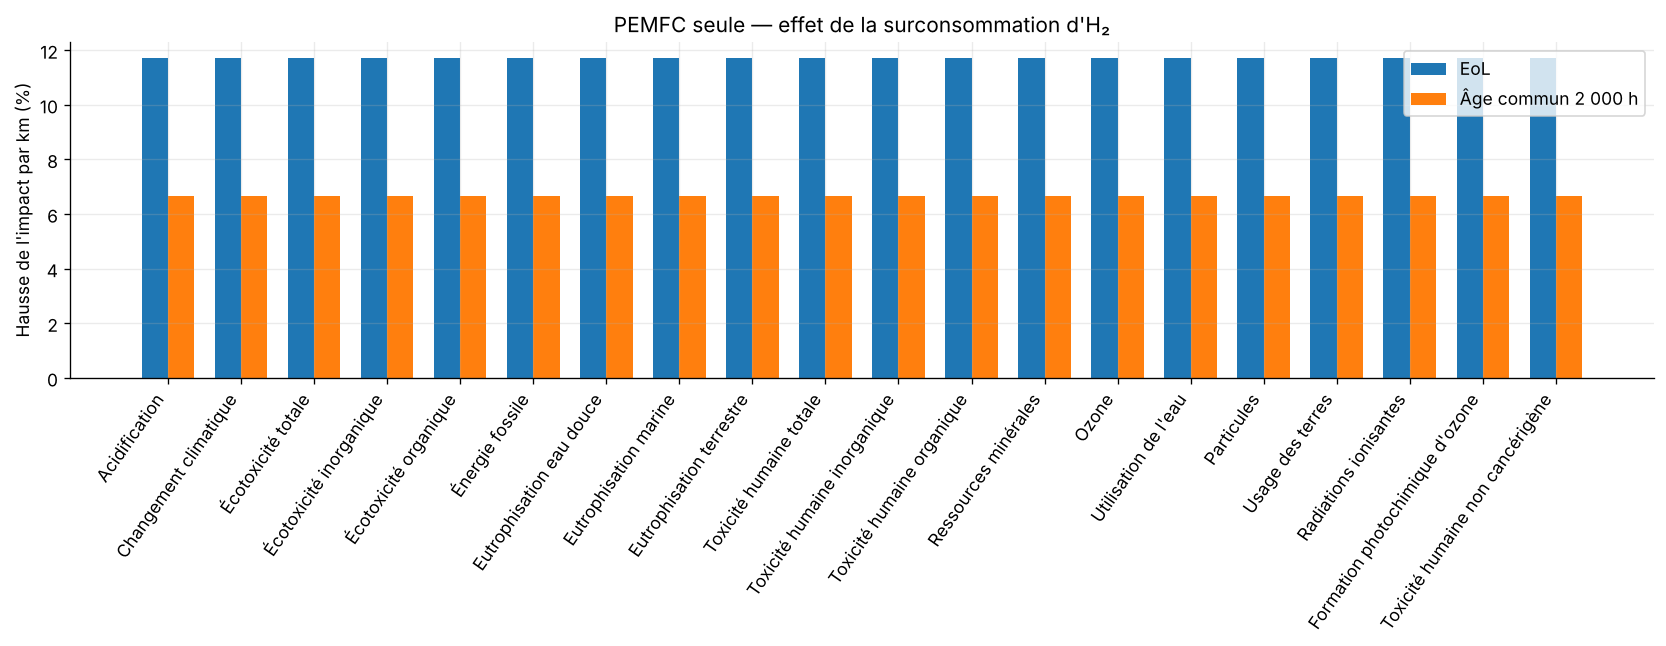

In [12]:
fc_ages={"Initial":0.,"Âge commun 2 000 h":AGE_FC,"EoL":fc_eol(FC_CENTRAL)}
h2_intensity0=impactkg(WE_SEC0);rows=[]
ifc0=FC_H2EXP0/DIST*h2_intensity0
for state,age in fc_ages.items():
 q=fc_state(age,FC_CENTRAL);imp=q["H2"]/DIST*h2_intensity0
 for ind in IND:rows.append({"État":state,"Age_PEMFC_h":age,"Indicateur":ind,"Impact_PEMFC_par_km":imp[ind],"Hausse_pct":pct(imp[ind],ifc0[ind])})
acv_fc=pd.DataFrame(rows);display(acv_fc.pivot(index="Indicateur",columns="État",values="Impact_PEMFC_par_km"))
q=acv_fc[acv_fc.État!="Initial"].pivot(index="Indicateur",columns="État",values="Hausse_pct").loc[IND]
fig,ax=plt.subplots(figsize=(14,5.5));x=np.arange(len(IND));wbar=.36
for n,c in enumerate(q.columns):ax.bar(x+(n-.5)*wbar,q[c],wbar,label=c)
ax.set_xticks(x,IND,rotation=55,ha="right");ax.set_ylabel("Hausse de l'impact par km (%)");ax.set_title("PEMFC seule — effet de la surconsommation d'H₂");ax.legend()
fig.tight_layout();fig.savefig(OUT/"ACV_02_PEMFC_seule.png",dpi=220);plt.show()


## 10.3 Impacts de la chaîne couplée

Le couplage combine simultanément la consommation d'H₂ de la PEMFC et la SEC du PEMWE :

$$IC^{chaine}_{k,km}(t_{FC},t_{WE})=
\frac{m_{H_2,cycle}(t_{FC})}{d_{WLTP}}
\frac{SEC(t_{WE})FE_{elec,k}+IC_{eau,k}+IC_{comp,k}}{1-L_{H_2}}.$$

Le cas à âge commun utilise 2 000 h PEMFC et l'âge PEMWE correspondant au calendrier avec 6 000 h/an. Une intégration temporelle calcule ensuite les impacts cumulés sur la même distance parcourue.


État,EoL des deux modèles,Initial,Âge commun
Indicateur,,,
Acidification,1.788201e-04,1.428522e-04,1.656287e-04
Changement climatique,5.436620e-02,4.342228e-02,5.035306e-02
Eutrophisation eau douce,7.646039e-06,6.108325e-06,7.082060e-06
Eutrophisation marine,6.809729e-05,5.438808e-05,6.307020e-05
Eutrophisation terrestre,4.583130e-04,3.660645e-04,4.244847e-04
Formation photochimique d'ozone,1.679183e-04,1.341187e-04,1.555238e-04
Ozone,1.638728e-09,1.310374e-09,1.518216e-09
Particules,3.094184e-09,2.471406e-09,2.865806e-09
Radiations ionisantes,4.347688e-01,3.472108e-01,4.026639e-01


,Indicateur,Impact_cumulé_neuf,Impact_cumulé_vieilli,Hausse_pct
0,Acidification,1.028738e+01,1.118747e+01,8.749400
1,Changement climatique,3.127021e+03,3.400911e+03,8.758838
2,Écotoxicité totale,6.715943e+03,7.286273e+03,8.492179
3,Écotoxicité inorganique,6.571567e+03,7.129270e+03,8.486613
4,Écotoxicité organique,1.443767e+02,1.570033e+02,8.745538
5,Énergie fossile,5.488882e+05,5.969918e+05,8.763829
6,Eutrophisation eau douce,4.398861e-01,4.783663e-01,8.747754
7,Eutrophisation marine,3.916714e+00,4.259814e+00,8.759902
8,Eutrophisation terrestre,2.636184e+01,2.867049e+01,8.757558
9,Toxicité humaine totale,9.220050e-07,1.002468e-06,8.726976


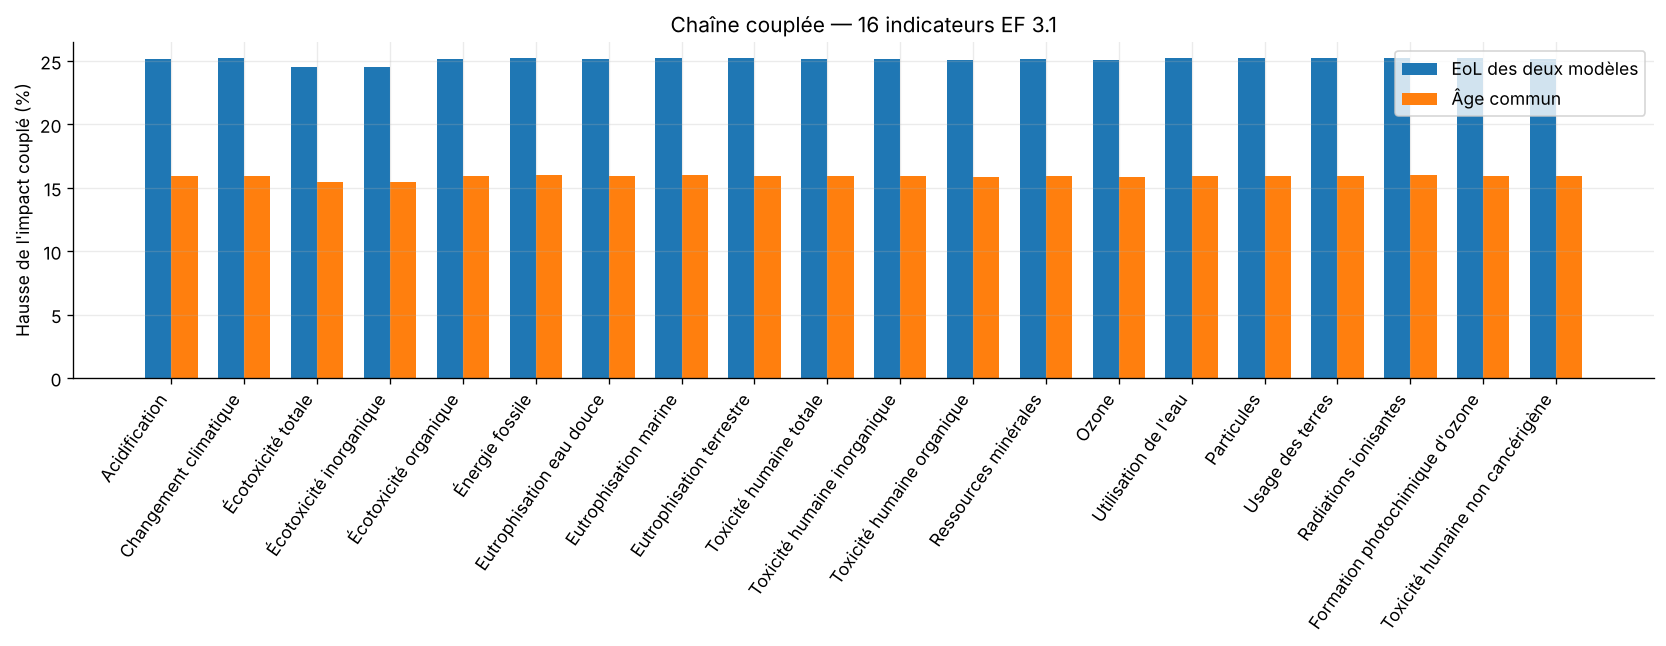

In [13]:
AGE_WE_COUPLED=AGE_FC/HFC_AN*6000
states={"Initial":(0.,0.),"Âge commun":(AGE_FC,AGE_WE_COUPLED),"EoL des deux modèles":(fc_eol(FC_CENTRAL),we_eol(WE_CENTRAL))}
rows=[];coupled0=FC_H2EXP0/DIST*impactkg(WE_SEC0)
for state,(af,aw) in states.items():
 sf=fc_state(af,FC_CENTRAL);sw=we_state(aw,WE_CENTRAL);imp=sf["H2"]/DIST*impactkg(sw["SEC"])
 for ind in IND:rows.append({"État":state,"Age_FC_h":af,"Age_WE_h":aw,"Indicateur":ind,"Impact_chaine_par_km":imp[ind],"Hausse_pct":pct(imp[ind],coupled0[ind])})
acv_chain=pd.DataFrame(rows);display(acv_chain.pivot(index="Indicateur",columns="État",values="Impact_chaine_par_km"))

# Intégration centrale de 0 à 2000 h PEMFC.
grid=np.linspace(0,AGE_FC,61);h2=[];sec=[]
for a in grid:
 h2.append(fc_state(a,FC_CENTRAL)["H2"]);sec.append(float(we_state(a/HFC_AN*6000,WE_CENTRAL)["SEC"]))
h2=np.asarray(h2);sec=np.asarray(sec);cycles_h=1/DUR
cum_rows=[]
for ind in IND:
 rate=cycles_h*h2*(sec*FE[ind]+EAU[ind]+COMP3[ind]*E_COMP/3);ref_rate=cycles_h*FC_H2EXP0*impactkg(WE_SEC0)[ind]
 aged=float(trapz(rate,grid));ref=float(ref_rate*AGE_FC)
 cum_rows.append({"Indicateur":ind,"Impact_cumulé_neuf":ref,"Impact_cumulé_vieilli":aged,"Hausse_pct":pct(aged,ref)})
acv_cum=pd.DataFrame(cum_rows);display(acv_cum)
q=acv_chain[acv_chain.État!="Initial"].pivot(index="Indicateur",columns="État",values="Hausse_pct").loc[IND]
fig,ax=plt.subplots(figsize=(14,5.5));x=np.arange(len(IND));wbar=.36
for n,c in enumerate(q.columns):ax.bar(x+(n-.5)*wbar,q[c],wbar,label=c)
ax.set_xticks(x,IND,rotation=55,ha="right");ax.set_ylabel("Hausse de l'impact couplé (%)");ax.set_title("Chaîne couplée — 16 indicateurs EF 3.1");ax.legend()
fig.tight_layout();fig.savefig(OUT/"ACV_03_chaine_couplee.png",dpi=220);plt.show()


## 10.4 Impacts cumulés jusqu'à la fin de vie propre de chaque équipement

Un impact observé uniquement au dernier instant ne représente pas toute la vie. Les impacts sont donc intégrés depuis l'état neuf jusqu'à l'EoL propre de l'équipement.

### PEMFC seule

Le cycle WLTP est répété. La distance reste identique dans les cas neuf et vieilli, mais la pile vieillie consomme plus d'H₂ :

$$IC^{FC,cum}_k=\int_0^{t_{EoL,FC}}N_{cycle/h}\,m_{H_2,cycle}(t)\,IC_{k,kgH_2,0}\,dt.$$

La référence est une pile artificiellement maintenue neuve pendant la même durée. L'électricité de production de l'H₂ reste au niveau initial afin d'isoler le seul effet du vieillissement PEMFC.

### PEMWE seul

Le profil expérimental de quatre heures est répété jusqu'à l'EoL PEMWE :

$$IC^{WE,cum}_k=\int_0^{t_{EoL,WE}}\dot m_{H_2}(t)
\left[SEC(t)FE_{elec,k}+IC_{eau,k}\right]dt.$$

Comme le rendement faradique modifie la quantité produite, deux résultats sont fournis : l'impact total cumulé réel et l'impact moyen sur la vie par kilogramme effectivement produit. La comparaison environnementale principale utilise ce second résultat, donc le même service de 1 kg H₂.

### Chaîne complète

Les deux équipements vieillissent avec leurs horloges propres. La chaîne est intégrée jusqu'à la **première EoL calendaire**. Il n'y a aucun remplacement dans ce calcul de première vie.


,Système,EoL_fonctionnement_h,EoL_calendaire_ans,Service_total,Unité_service,Hausse_GWP_pct
0,PEMFC seule,3827.8967,10.3374,137831.4481,véhicule·km,6.3082
1,PEMWE seul,46533.2759,7.7555,613632.3045,kg H2 net,6.8772
2,Chaîne jusqu'à première EoL,2871.8583,7.7555,103407.2798,véhicule·km,11.8966


<cell 14>:67: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


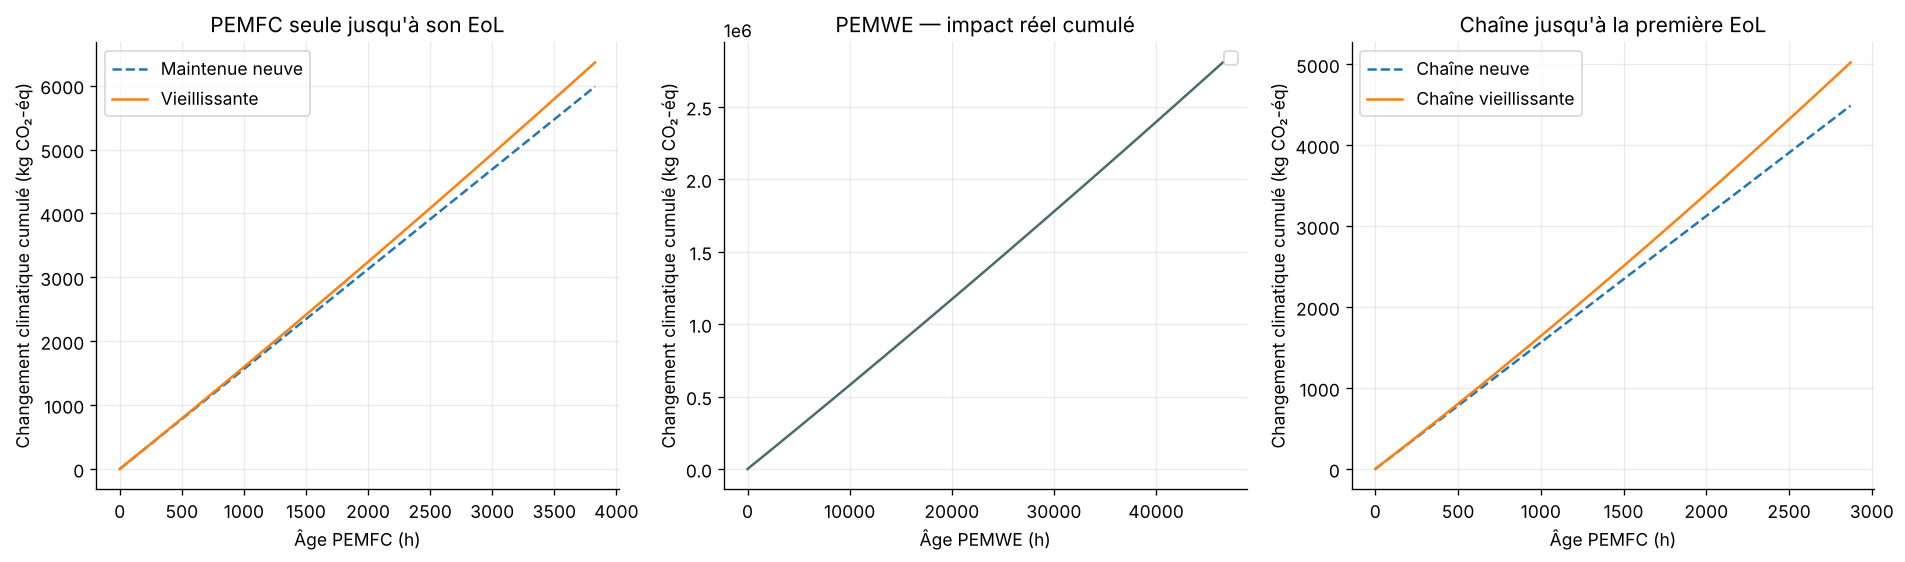

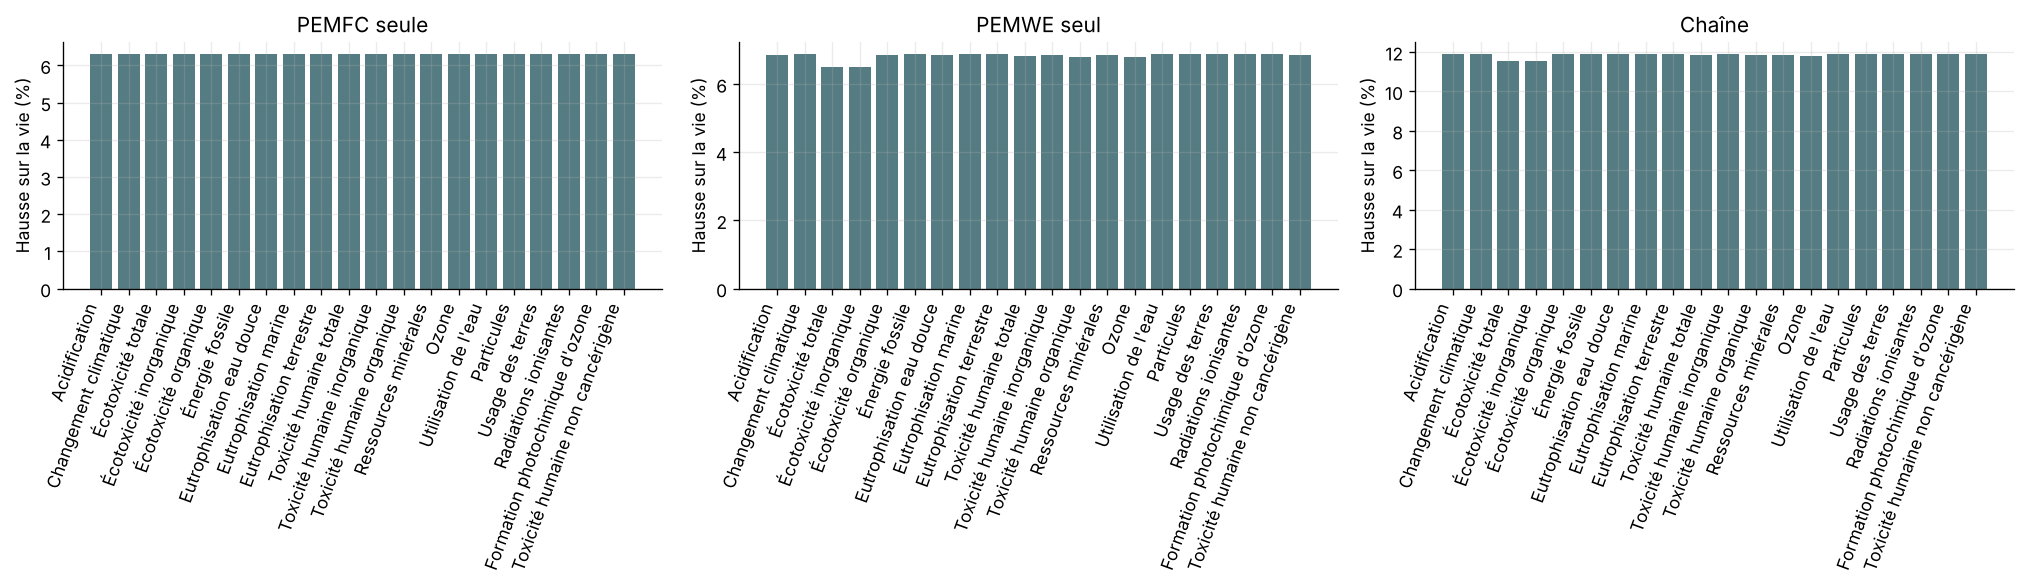

In [14]:
# ---------- PEMFC seule : cumul de 0 à son EoL ----------
EOL_FC=float(fc_eol(FC_CENTRAL));gfc=np.linspace(0,EOL_FC,301)
h2fc=np.array([fc_state(a,FC_CENTRAL)["H2"] for a in gfc]);cycles_h=1/DUR
distance_fc=cycles_h*DIST*EOL_FC
h2_fc_aged=float(trapz(cycles_h*h2fc,gfc));h2_fc_ref=float(cycles_h*FC_H2EXP0*EOL_FC)
rows=[]
for ind in IND:
 aged=float(trapz(cycles_h*h2fc*h2_intensity0[ind],gfc))
 ref=float(cycles_h*FC_H2EXP0*h2_intensity0[ind]*EOL_FC)
 rows.append({"Indicateur":ind,"EoL_PEMFC_h":EOL_FC,"Distance_totale_km":distance_fc,
              "H2_neuf_kg":h2_fc_ref,"H2_vieilli_kg":h2_fc_aged,
              "Impact_cumule_neuf":ref,"Impact_cumule_vieilli":aged,"Hausse_pct":pct(aged,ref)})
acv_fc_life=pd.DataFrame(rows)

# Trajectoire climatique cumulée PEMFC.
rate_fc=cycles_h*h2fc*h2_intensity0[GWP];cum_fc=np.r_[0,np.cumsum((rate_fc[1:]+rate_fc[:-1])*np.diff(gfc)/2)]
cum_fc_ref=cycles_h*FC_H2EXP0*h2_intensity0[GWP]*gfc

# ---------- PEMWE seul : cumul de 0 à son EoL ----------
EOL_WE=float(we_eol(WE_CENTRAL));gwe=np.linspace(0,EOL_WE,301)
qwe=[we_state(a,WE_CENTRAL) for a in gwe]
h2we=np.array([float(q["H2"]) for q in qwe]);secwe=np.array([float(q["SEC"]) for q in qwe])
PROFILE_WE_H=4.;h2rate_we=h2we/PROFILE_WE_H
h2_we_aged=float(trapz(h2rate_we,gwe));h2_we_ref=float(WE_H20/PROFILE_WE_H*EOL_WE)
rows=[]
for ind in IND:
 intensity=np.array([impact_we_only(s)[ind] for s in secwe])
 cumulative=float(trapz(h2rate_we*intensity,gwe))
 intensity_life=cumulative/h2_we_aged
 ref_intensity=float(iw0[ind])
 rows.append({"Indicateur":ind,"EoL_PEMWE_h":EOL_WE,"H2_total_vieilli_kg":h2_we_aged,
              "H2_total_si_neuf_kg":h2_we_ref,"Impact_cumule_reel":cumulative,
              "Impact_moyen_vie_par_kgH2":intensity_life,"Impact_neuf_par_kgH2":ref_intensity,
              "Hausse_intensite_pct":pct(intensity_life,ref_intensity)})
acv_we_life=pd.DataFrame(rows)
rate_we_gwp=h2rate_we*np.array([impact_we_only(s)[GWP] for s in secwe])
cum_we=np.r_[0,np.cumsum((rate_we_gwp[1:]+rate_we_gwp[:-1])*np.diff(gwe)/2)]

# ---------- Chaîne : cumul jusqu'à la première EoL calendaire ----------
HWE_AN=6000.;cal_eol_fc=EOL_FC/HFC_AN;cal_eol_we=EOL_WE/HWE_AN
cal_stop=min(cal_eol_fc,cal_eol_we);fc_stop=cal_stop*HFC_AN;we_stop=cal_stop*HWE_AN
gc=np.linspace(0,fc_stop,301);h2c=np.array([fc_state(a,FC_CENTRAL)["H2"] for a in gc])
we_age_c=gc/HFC_AN*HWE_AN;secc=np.array([float(we_state(a,WE_CENTRAL)["SEC"]) for a in we_age_c])
rows=[]
for ind in IND:
 intens=np.array([impactkg(s)[ind] for s in secc]);aged=float(trapz(cycles_h*h2c*intens,gc))
 ref=float(cycles_h*FC_H2EXP0*impactkg(WE_SEC0)[ind]*fc_stop)
 rows.append({"Indicateur":ind,"Horizon_calendaire_ans":cal_stop,"Age_final_PEMFC_h":fc_stop,
              "Age_final_PEMWE_h":we_stop,"Premier_EOL":"PEMFC" if cal_eol_fc<=cal_eol_we else "PEMWE",
              "Distance_totale_km":cycles_h*DIST*fc_stop,"Impact_cumule_neuf":ref,
              "Impact_cumule_vieilli":aged,"Hausse_pct":pct(aged,ref)})
acv_chain_life=pd.DataFrame(rows)
rate_chain=cycles_h*h2c*np.array([impactkg(s)[GWP] for s in secc])
cum_chain=np.r_[0,np.cumsum((rate_chain[1:]+rate_chain[:-1])*np.diff(gc)/2)]
cum_chain_ref=cycles_h*FC_H2EXP0*impactkg(WE_SEC0)[GWP]*gc

summary_life=pd.DataFrame([
 {"Système":"PEMFC seule","EoL_fonctionnement_h":EOL_FC,"EoL_calendaire_ans":cal_eol_fc,"Service_total":distance_fc,"Unité_service":"véhicule·km","Hausse_GWP_pct":float(acv_fc_life.loc[acv_fc_life.Indicateur==GWP,"Hausse_pct"].iloc[0])},
 {"Système":"PEMWE seul","EoL_fonctionnement_h":EOL_WE,"EoL_calendaire_ans":cal_eol_we,"Service_total":h2_we_aged,"Unité_service":"kg H2 net","Hausse_GWP_pct":float(acv_we_life.loc[acv_we_life.Indicateur==GWP,"Hausse_intensite_pct"].iloc[0])},
 {"Système":"Chaîne jusqu'à première EoL","EoL_fonctionnement_h":fc_stop,"EoL_calendaire_ans":cal_stop,"Service_total":cycles_h*DIST*fc_stop,"Unité_service":"véhicule·km","Hausse_GWP_pct":float(acv_chain_life.loc[acv_chain_life.Indicateur==GWP,"Hausse_pct"].iloc[0])}])
display(summary_life.round(4))

fig,axs=plt.subplots(1,3,figsize=(16,4.8))
axs[0].plot(gfc,cum_fc_ref,label="Maintenue neuve",ls="--");axs[0].plot(gfc,cum_fc,label="Vieillissante")
axs[1].plot(gwe,cum_we,color="#476F68");axs[1].set_title("PEMWE — impact réel cumulé")
axs[2].plot(gc,cum_chain_ref,label="Chaîne neuve",ls="--");axs[2].plot(gc,cum_chain,label="Chaîne vieillissante")
for ax,xlab in zip(axs,["Âge PEMFC (h)","Âge PEMWE (h)","Âge PEMFC (h)"]):ax.set(xlabel=xlab,ylabel="Changement climatique cumulé (kg CO₂-éq)");ax.legend()
axs[0].set_title("PEMFC seule jusqu'à son EoL");axs[2].set_title("Chaîne jusqu'à la première EoL")
fig.tight_layout();fig.savefig(OUT/"ACV_04_impacts_cumules_jusqua_EOL.png",dpi=220);plt.show()

fig,axs=plt.subplots(1,3,figsize=(17,5));tables=[(acv_fc_life,"Hausse_pct","PEMFC seule"),(acv_we_life,"Hausse_intensite_pct","PEMWE seul"),(acv_chain_life,"Hausse_pct","Chaîne")]
for ax,(tab,col,title) in zip(axs,tables):ax.bar(np.arange(len(IND)),tab[col],color="#557C83");ax.set_xticks(np.arange(len(IND)),IND,rotation=70,ha="right");ax.set(title=title,ylabel="Hausse sur la vie (%)")
fig.tight_layout();fig.savefig(OUT/"ACV_05_16_indicateurs_cumules_EOL.png",dpi=220);plt.show()


## 11. Sensibilité locale du couplage

L'horizon commun est 2000 h PEMFC. Cela garantit le même service et évite de comparer des systèmes ayant fonctionné pendant des durées différentes.

Le temps PEMWE correspondant est calculé par le calendrier :

$$t_{WE}=\frac{t_{FC}}{H_{FC,an}}H_{WE,an}.$$

Le cas central utilise $H_{WE,an}=6000$ h/an. La sensibilité couvre les constantes de vieillissement des deux composants, les pertes H₂, la compression et le facteur d'impact électrique.


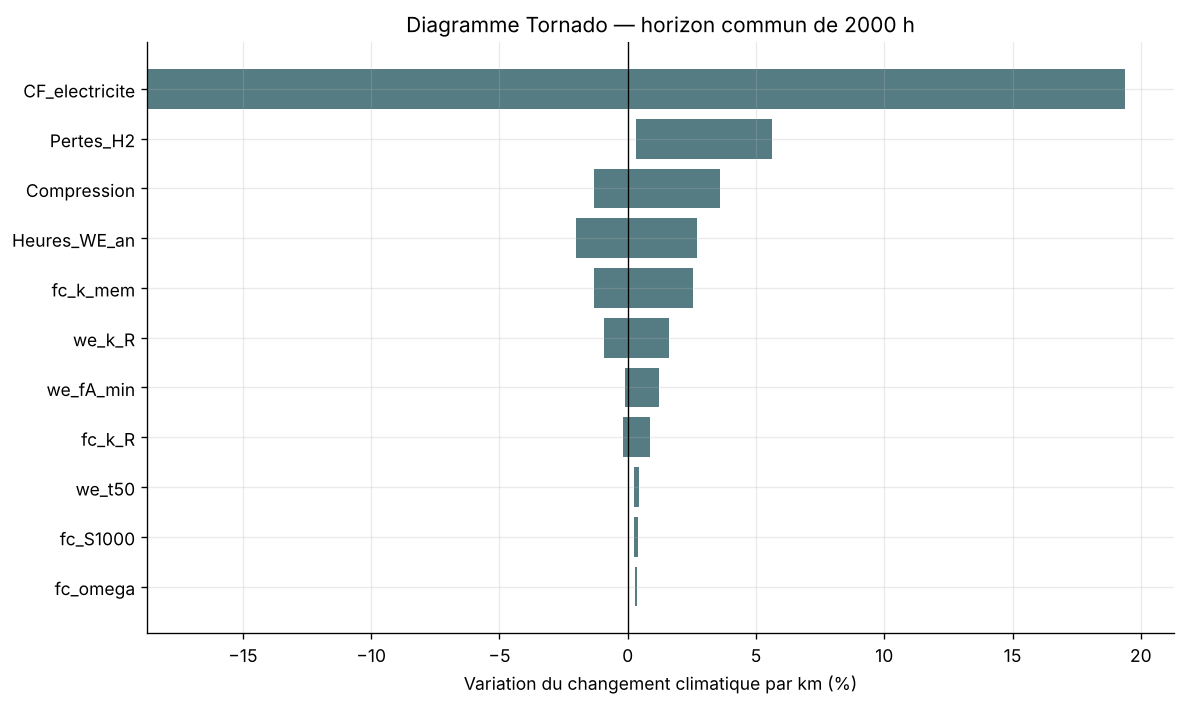

,Paramètre,Minimum_pct,Maximum_pct,Amplitude
0,fc_omega,0.293,0.380,0.087
1,fc_S1000,0.255,0.397,0.142
6,we_t50,0.253,0.431,0.178
2,fc_k_R,-0.188,0.870,1.058
5,we_fA_min,-0.117,1.223,1.340
4,we_k_R,-0.943,1.594,2.538
3,fc_k_mem,-1.312,2.557,3.870
7,Heures_WE_an,-2.009,2.694,4.703
9,Compression,-1.302,3.580,4.882
8,Pertes_H2,0.325,5.606,5.280


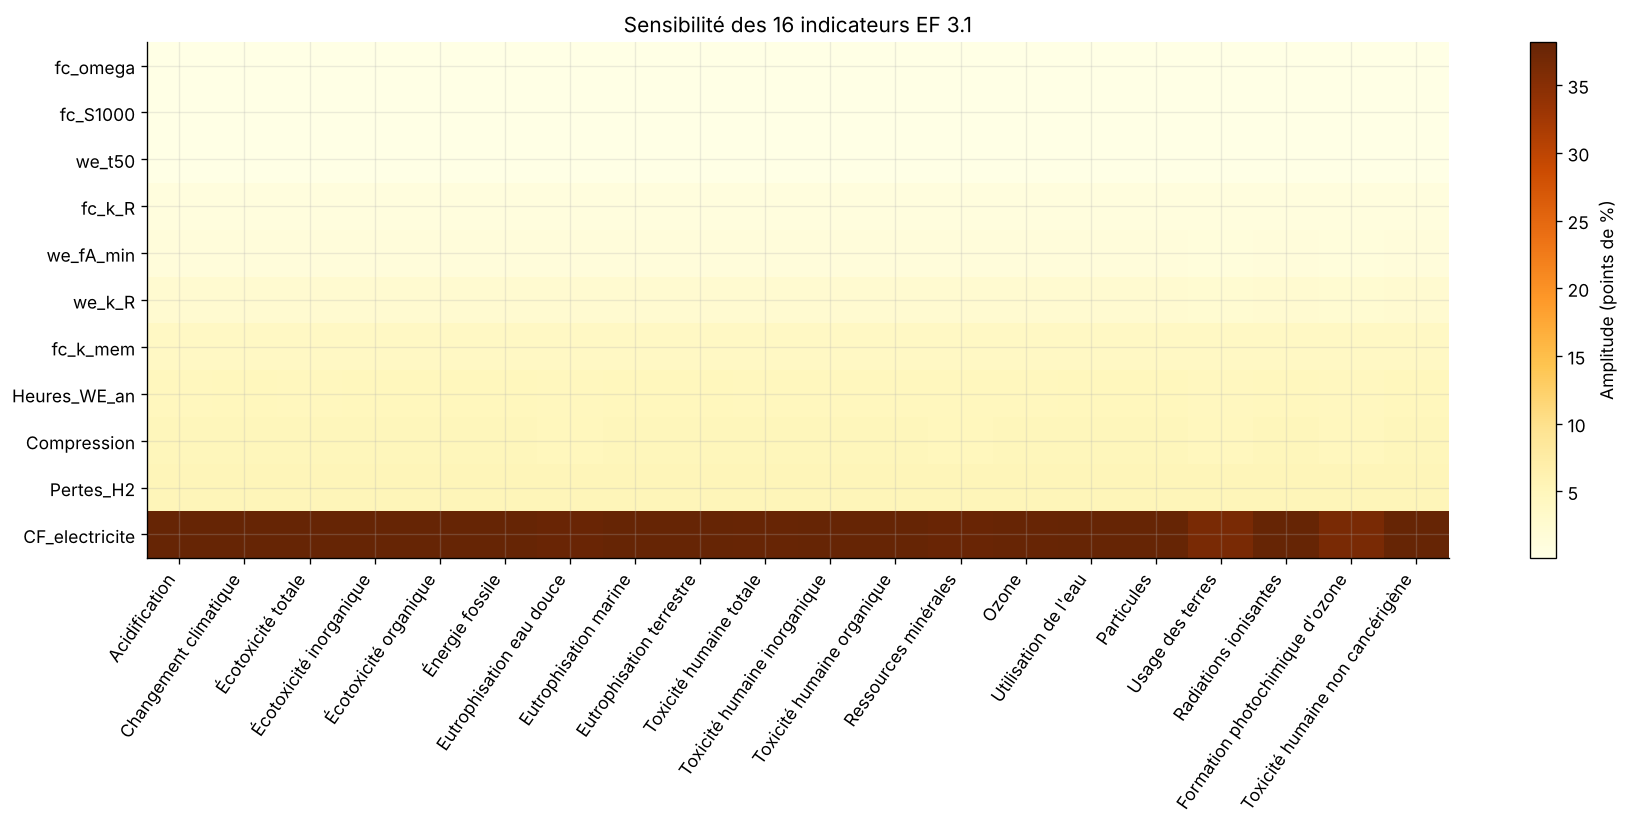

In [15]:
HORIZON=2000.;HWE_AN=6000.
def coupled_endpoint(pfc,pwe,hwe=HWE_AN,loss=0,comp=E_COMP,cf=1):
 sf=fc_state(HORIZON,pfc);twe=HORIZON/HFC_AN*hwe;sw=we_state(twe,pwe)
 ikm=sf["H2"]/DIST*impactkg(float(sw["SEC"]),loss,comp,cf)
 return sf,float(twe),sw,ikm

# Constantes de vieillissement : valeurs publiées.
tests={"fc_omega":[FC_BOUNDS["omega"][0],FC_CENTRAL["omega"],FC_BOUNDS["omega"][1]],
       "fc_S1000":[FC_BOUNDS["S1000"][0],FC_CENTRAL["S1000"],FC_BOUNDS["S1000"][1]],
       "fc_k_R":[FC_BOUNDS["k_R"][0],FC_CENTRAL["k_R"],FC_BOUNDS["k_R"][1]],
       "fc_k_mem":[FC_BOUNDS["k_mem"][0],FC_CENTRAL["k_mem"],FC_BOUNDS["k_mem"][1]],
       "we_k_R":[WE_SCEN[n]["k_R"] for n in WE_SCEN],"we_fA_min":[PADGETT["fA_masse"],PADGETT["fA_capa"]],
       "we_t50":[CHANDESRIS_T50["couple"],CHANDESRIS_T50["lineaire"]],
       "Heures_WE_an":[4000,6000,8000],"Pertes_H2":[0,.01,.03,.05],"Compression":[2,3,5],"CF_electricite":[.8,1,1.2]}
rows=[];base=coupled_endpoint(FC_CENTRAL,WE_CENTRAL)[3]
for par in tests:
 vals=tests[par]
 for val in vals:
  pf=FC_CENTRAL.copy();pw=WE_CENTRAL.copy();kw={"fc_omega":"omega","fc_S1000":"S1000","fc_k_R":"k_R","fc_k_mem":"k_mem"}.get(par)
  if kw:pf[kw]=val
  kw={"we_k_R":"k_R","we_fA_min":"fA_min","we_t50":"t50_mem"}.get(par)
  if kw:pw[kw]=val
  h=val if par=="Heures_WE_an" else HWE_AN;l=val if par=="Pertes_H2" else 0;c=val if par=="Compression" else 3;cf=val if par=="CF_electricite" else 1
  sf,tw,sw,ik=coupled_endpoint(pf,pw,h,l,c,cf)
  for ind in IND:rows.append({"Paramètre":par,"Valeur":val,"Indicateur":ind,"Impact_par_km":ik[ind],"Écart_pct":pct(ik[ind],base[ind])})
coupled_sens=pd.DataFrame(rows)
tornado=[]
for par in tests:
 q=coupled_sens[(coupled_sens.Paramètre==par)&(coupled_sens.Indicateur==GWP)]
 tornado.append({"Paramètre":par,"Minimum_pct":q.Écart_pct.min(),"Maximum_pct":q.Écart_pct.max(),"Amplitude":q.Écart_pct.max()-q.Écart_pct.min()})
tornado=pd.DataFrame(tornado).sort_values("Amplitude")
fig,ax=plt.subplots(figsize=(10,6));ax.barh(tornado.Paramètre,tornado.Maximum_pct-tornado.Minimum_pct,left=tornado.Minimum_pct,color="#557C83")
ax.axvline(0,color="black",lw=.8);ax.set(xlabel="Variation du changement climatique par km (%)",title="Diagramme Tornado — horizon commun de 2000 h")
fig.tight_layout();fig.savefig(OUT/"COUPLAGE_01_tornado.png",dpi=220);plt.show();display(tornado.round(3))

# Carte de sensibilité des 16 indicateurs : amplitude max-min pour chaque paramètre.
heat=coupled_sens.groupby(["Paramètre","Indicateur"]).Écart_pct.agg(lambda x:x.max()-x.min()).unstack().loc[tornado.Paramètre]
fig,ax=plt.subplots(figsize=(15,7));im=ax.imshow(heat,cmap="YlOrBr",aspect="auto")
ax.set_yticks(range(len(heat)),heat.index);ax.set_xticks(range(len(IND)),IND,rotation=55,ha="right");fig.colorbar(im,ax=ax,label="Amplitude (points de %)")
ax.set_title("Sensibilité des 16 indicateurs EF 3.1");fig.tight_layout();fig.savefig(OUT/"COUPLAGE_02_sensibilite_16_indicateurs.png",dpi=220);plt.show()


## 11.1 Figures supplémentaires — influence directe des paramètres sur l’ACV

Les figures précédentes décrivent les réponses techniques (durée de vie, consommation d'hydrogène et SEC). Les figures suivantes traduisent ces réponses en impacts environnementaux.

Toutes les comparaisons locales sont réalisées au même âge afin de ne pas confondre l'effet du paramètre avec une durée d'exposition différente :

- PEMFC : 2 000 h de fonctionnement ;
- PEMWE : 15 000 h de fonctionnement ;
- chaîne couplée : 2 000 h de PEMFC, avec l'âge PEMWE correspondant à 6 000 h/an.

Un écart positif signifie que l'hypothèse testée augmente l'impact par rapport au cas central. Un écart négatif signifie qu'elle le réduit. Les résultats ne sont donc pas des impacts absolus, mais des variations relatives autour du modèle central.


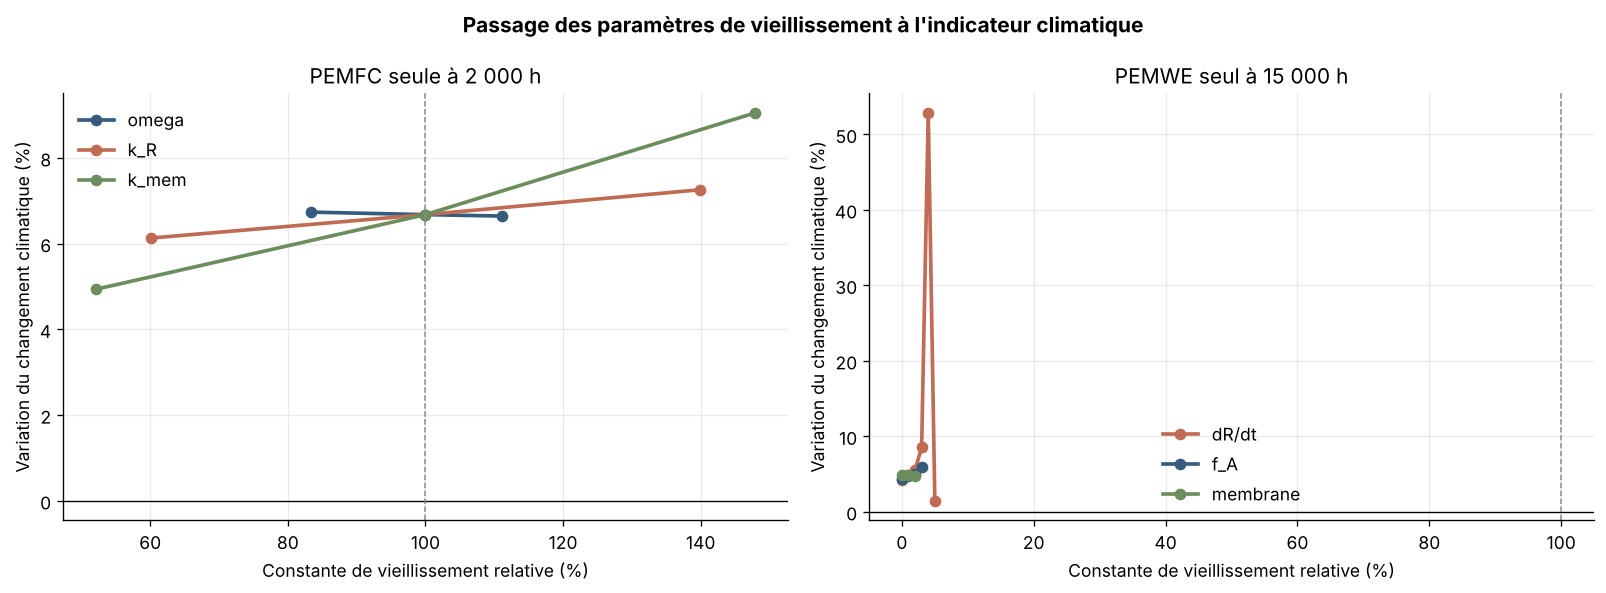

In [16]:
# ---------- Construction des sensibilités ACV propres à chaque équipement ----------
def central_index(values, target):
    values=np.asarray(values,dtype=float)
    return int(np.argmin(np.abs(values-float(target))))

# PEMFC seule : le vieillissement modifie la quantité de H2 consommée par km.
fc_acv_rows=[]
for par in ["omega","k_R","k_mem"]:
    q=fc_sens[fc_sens["Paramètre"]==par].sort_values("Valeur")
    for _,r in q.iterrows():
        impact=r.H2_2000h/DIST*h2_intensity0
        for ind in IND:
            fc_acv_rows.append({"Paramètre":par,"Valeur":r.Valeur,"Valeur_relative_pct":100*r.Valeur/FC_CENTRAL[par],
                                "Indicateur":ind,"Impact":impact[ind],"Écart_pct":pct(impact[ind],ifc0[ind])})
fc_acv_sens=pd.DataFrame(fc_acv_rows)

# PEMWE seul : le vieillissement modifie la SEC par kg H2 net.
we_acv_rows=[]
for par in ["dR/dt","f_A","membrane"]:
    q=we_sens[we_sens["Paramètre"]==par]
    for _,r in q.iterrows():
        impact=impact_we_only(r.SEC_15000h)
        for ind in IND:
            we_acv_rows.append({"Paramètre":par,"Valeur":r.Cas,"Valeur_relative_pct":np.nan,
                                "Indicateur":ind,"Impact":impact[ind],"Écart_pct":pct(impact[ind],iw0[ind])})
we_acv_sens=pd.DataFrame(we_acv_rows)

# Figure A : réponse climatique directe des constantes de vieillissement.
fig,axs=plt.subplots(1,2,figsize=(13.5,5))
palette={"omega":"#355C7D","k_R":"#C06C54","k_mem":"#6C8E5E","k_F":"#6C8E5E"}
for par in ["omega","k_R","k_mem"]:
    q=fc_acv_sens[(fc_acv_sens.Paramètre==par)&(fc_acv_sens.Indicateur==GWP)]
    axs[0].plot(q.Valeur_relative_pct,q.Écart_pct,"o-",lw=2.2,label=par,color=palette[par])
for par,c in [("dR/dt","#C06C54"),("f_A","#355C7D"),("membrane","#6C8E5E")]:
    q=we_acv_sens[(we_acv_sens.Paramètre==par)&(we_acv_sens.Indicateur==GWP)]
    axs[1].plot(range(len(q)),q.Écart_pct,"o-",lw=2.2,label=par,color=c)
for ax,title in zip(axs,["PEMFC seule à 2 000 h","PEMWE seul à 15 000 h"]):
    ax.axhline(0,color="black",lw=.8);ax.axvline(100,color="0.55",ls="--",lw=.9)
    ax.set(xlabel="Constante de vieillissement relative (%)",ylabel="Variation du changement climatique (%)",title=title)
    ax.legend(frameon=False);ax.grid(alpha=.25)
fig.suptitle("Passage des paramètres de vieillissement à l'indicateur climatique",fontweight="bold")
fig.tight_layout();fig.savefig(OUT/"ACV_SENS_01_constantes_vers_climat.png",dpi=240,bbox_inches="tight");plt.show()


### Lecture de la figure

Chaque courbe ne fait varier qu'une seule constante de vieillissement, les autres restant à leur valeur centrale. La pente indique la direction de l'effet et son amplitude indique la sensibilité. Une courbe presque horizontale signifie que le paramètre influence peu l'indicateur climatique à l'âge retenu.


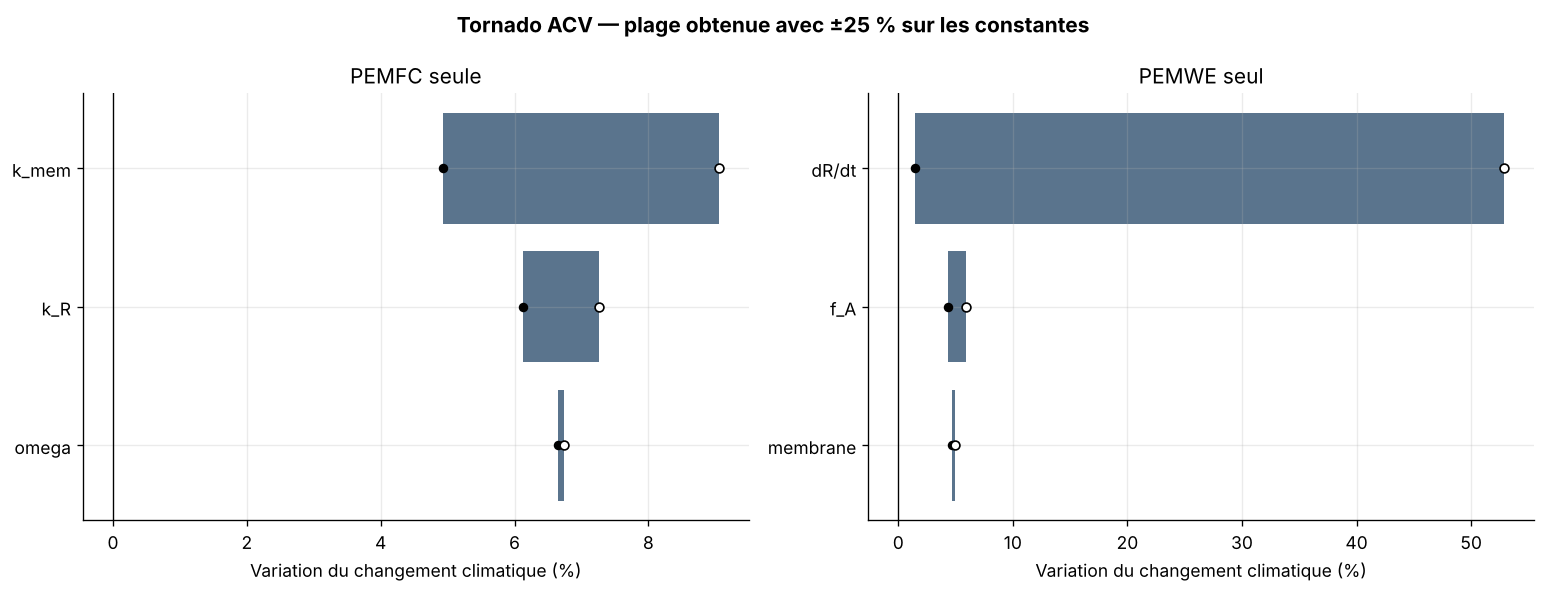

Paramètre  Minimum_pct  Maximum_pct  Amplitude
Système                                                 
PEMFC   0     omega       6.6424       6.7349     0.0924
        1       k_R       6.1306       7.2554     1.1248
        2     k_mem       4.9354       9.0499     4.1146
PEMWE   2  membrane       4.6996       4.9142     0.2146
        0       f_A       4.3673       5.8959     1.5286
        1     dR/dt       1.4440      52.8607    51.4166

In [17]:
# Figure B : diagrammes Tornado propres au PEMFC et au PEMWE.
def tornado_from_table(tab, parameters, indicator=GWP):
    rows=[]
    for par in parameters:
        q=tab[(tab.Paramètre==par)&(tab.Indicateur==indicator)]
        rows.append({"Paramètre":par,"Minimum_pct":q.Écart_pct.min(),"Maximum_pct":q.Écart_pct.max(),
                     "Amplitude":q.Écart_pct.max()-q.Écart_pct.min()})
    return pd.DataFrame(rows).sort_values("Amplitude")

t_fc=tornado_from_table(fc_acv_sens,["omega","k_R","k_mem"])
t_we=tornado_from_table(we_acv_sens,["f_A","dR/dt","membrane"])
fig,axs=plt.subplots(1,2,figsize=(13,5))
for ax,tab,title in zip(axs,[t_fc,t_we],["PEMFC seule","PEMWE seul"]):
    colors=["#486581" if b>=a else "#C06C54" for a,b in zip(tab.Minimum_pct,tab.Maximum_pct)]
    ax.barh(tab.Paramètre,tab.Maximum_pct-tab.Minimum_pct,left=tab.Minimum_pct,color=colors,alpha=.9)
    ax.scatter(tab.Minimum_pct,tab.Paramètre,color="black",s=22,zorder=3,label="minimum")
    ax.scatter(tab.Maximum_pct,tab.Paramètre,color="white",edgecolor="black",s=28,zorder=3,label="maximum")
    ax.axvline(0,color="black",lw=.8);ax.set(xlabel="Variation du changement climatique (%)",title=title);ax.grid(axis="x",alpha=.25)
fig.suptitle("Tornado ACV — plage obtenue avec ±25 % sur les constantes",fontweight="bold")
fig.tight_layout();fig.savefig(OUT/"ACV_SENS_02_tornado_equipements.png",dpi=240,bbox_inches="tight");plt.show()
display(pd.concat({"PEMFC":t_fc,"PEMWE":t_we},names=["Système"]).round(4))


### Lecture du Tornado

La longueur de chaque barre représente la plage de variation de l'impact climatique lorsque le paramètre passe de 75 % à 125 % de sa valeur centrale. La barre la plus longue désigne le paramètre le plus influent dans cette plage, sans prouver à elle seule une causalité générale hors de ce domaine.


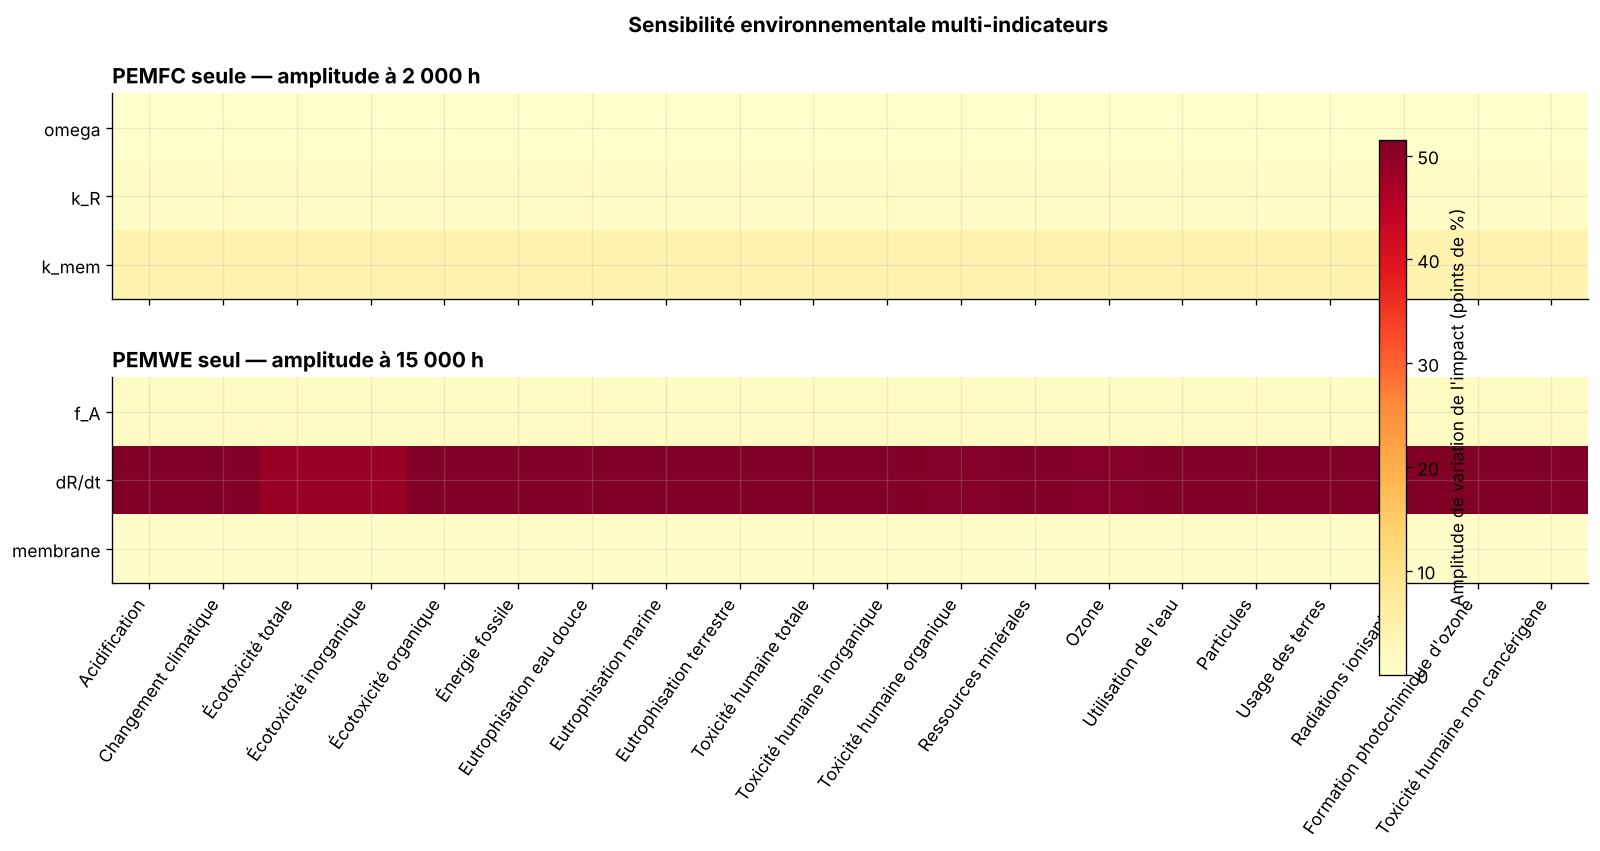

In [18]:
# Figure C : cartes de chaleur pour les 16 indicateurs EF 3.1.
def normalized_amplitude(tab, parameters):
    amp=tab.groupby(["Paramètre","Indicateur"]).Écart_pct.agg(lambda x:x.max()-x.min()).unstack()
    return amp.loc[parameters,IND]

heat_fc=normalized_amplitude(fc_acv_sens,["omega","k_R","k_mem"])
heat_we=normalized_amplitude(we_acv_sens,["f_A","dR/dt","membrane"])
vmax=max(float(heat_fc.max().max()),float(heat_we.max().max()))
fig,axs=plt.subplots(2,1,figsize=(15,6.8),sharex=True)
for ax,tab,title in zip(axs,[heat_fc,heat_we],["PEMFC seule — amplitude à 2 000 h","PEMWE seul — amplitude à 15 000 h"]):
    im=ax.imshow(tab,cmap="YlOrRd",aspect="auto",vmin=0,vmax=vmax)
    ax.set_yticks(range(len(tab)),tab.index);ax.set_title(title,loc="left",fontweight="bold")
axs[-1].set_xticks(range(len(IND)),IND,rotation=55,ha="right")
fig.colorbar(im,ax=axs,label="Amplitude de variation de l'impact (points de %)",shrink=.85)
fig.suptitle("Sensibilité environnementale multi-indicateurs",fontweight="bold")
fig.subplots_adjust(left=.08,right=.9,bottom=.28,top=.88,hspace=.38)
fig.savefig(OUT/"ACV_SENS_03_heatmaps_equipements.png",dpi=240,bbox_inches="tight");plt.show()


### Lecture des cartes de chaleur

Une case foncée signifie que l'indicateur environnemental varie fortement dans la plage testée. La carte permet de vérifier si le classement obtenu pour le changement climatique reste valable pour l'acidification, les toxicités, les ressources, l'eau et les autres indicateurs EF 3.1.


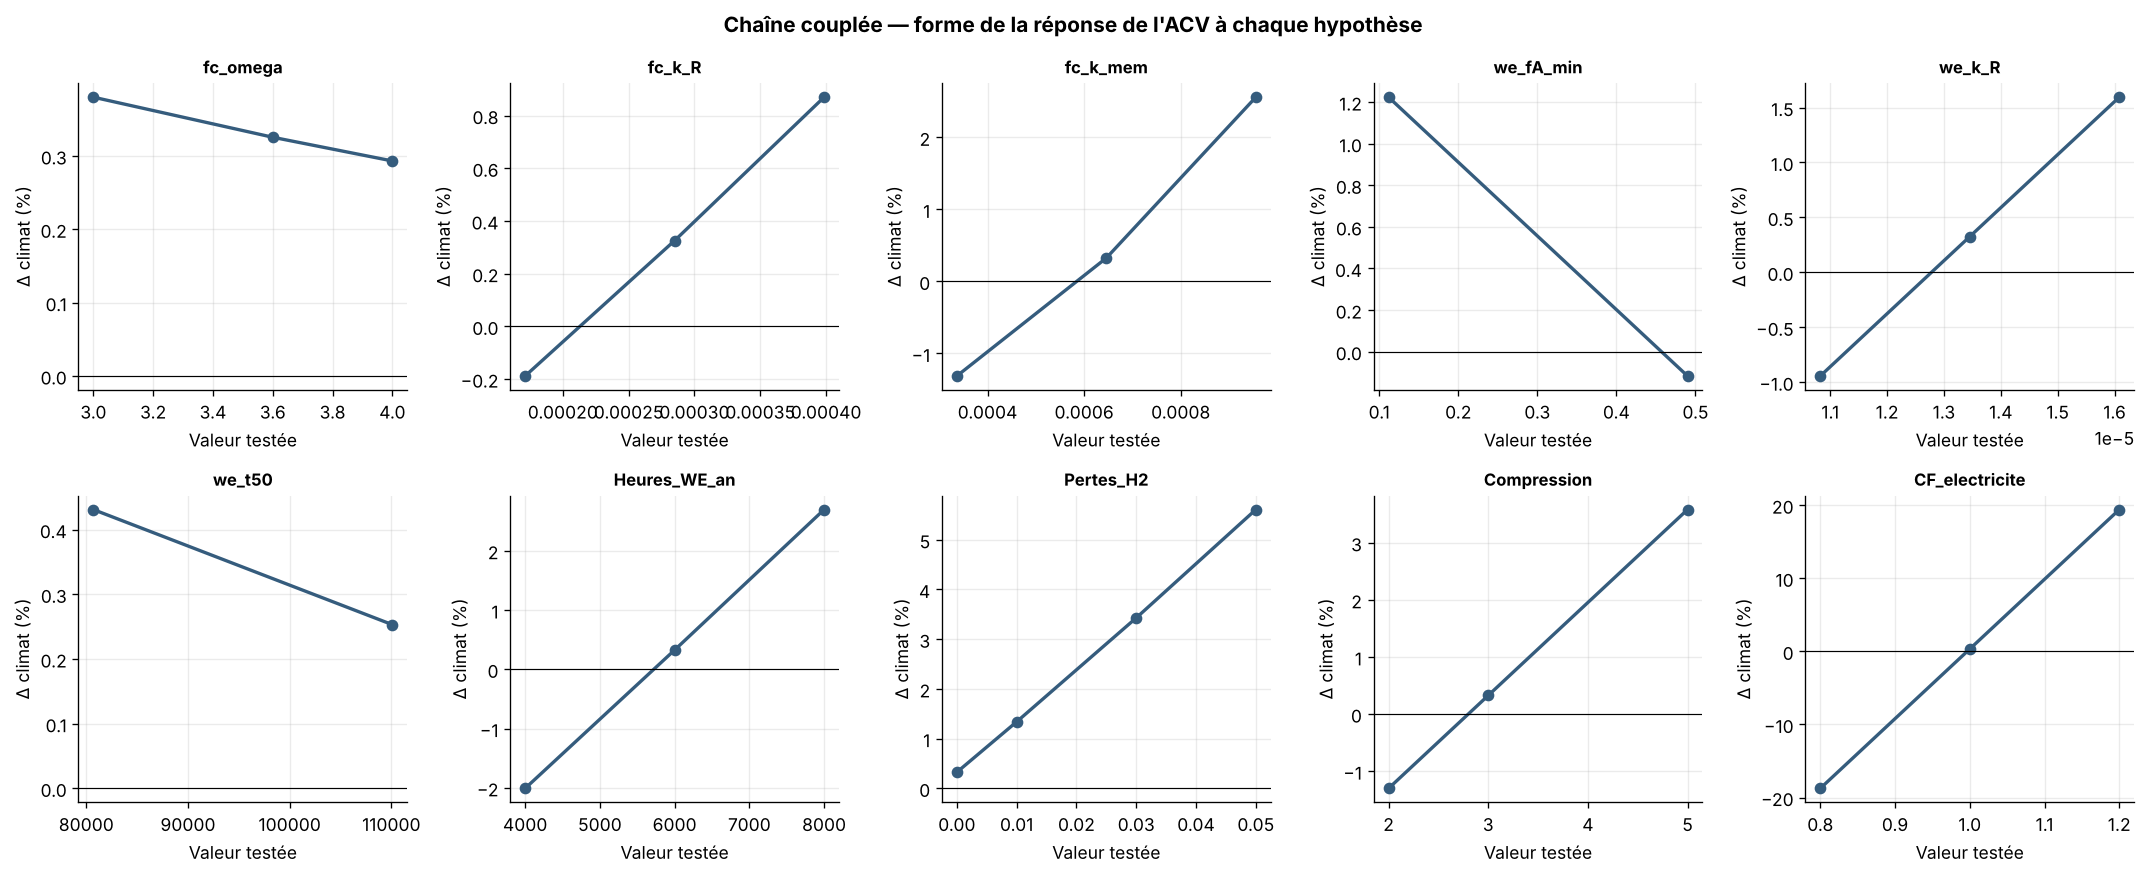

In [19]:
# Figure D : courbes de réponse de la chaîne pour les paramètres les plus importants.
selected=["fc_omega","fc_k_R","fc_k_mem","we_fA_min","we_k_R","we_t50","Heures_WE_an","Pertes_H2","Compression","CF_electricite"]
fig,axs=plt.subplots(2,5,figsize=(18,7.4));axs=axs.ravel()
for ax,par in zip(axs,selected):
    q=coupled_sens[(coupled_sens.Paramètre==par)&(coupled_sens.Indicateur==GWP)].sort_values("Valeur")
    ax.plot(q.Valeur,q.Écart_pct,"o-",color="#355C7D",lw=2)
    ax.axhline(0,color="black",lw=.7);ax.set_title(par,fontweight="bold",fontsize=10);ax.grid(alpha=.25)
    ax.set_xlabel("Valeur testée");ax.set_ylabel("Δ climat (%)")
fig.suptitle("Chaîne couplée — forme de la réponse de l'ACV à chaque hypothèse",fontweight="bold")
fig.tight_layout();fig.savefig(OUT/"ACV_SENS_04_reponses_couplage.png",dpi=240,bbox_inches="tight");plt.show()


### Pourquoi conserver ces courbes en plus du Tornado ?

Le Tornado résume seulement les valeurs extrêmes. Les courbes de réponse montrent si l'effet est approximativement linéaire, faible, monotone ou fortement non linéaire. Elles évitent donc d'interpréter abusivement une simple amplitude.


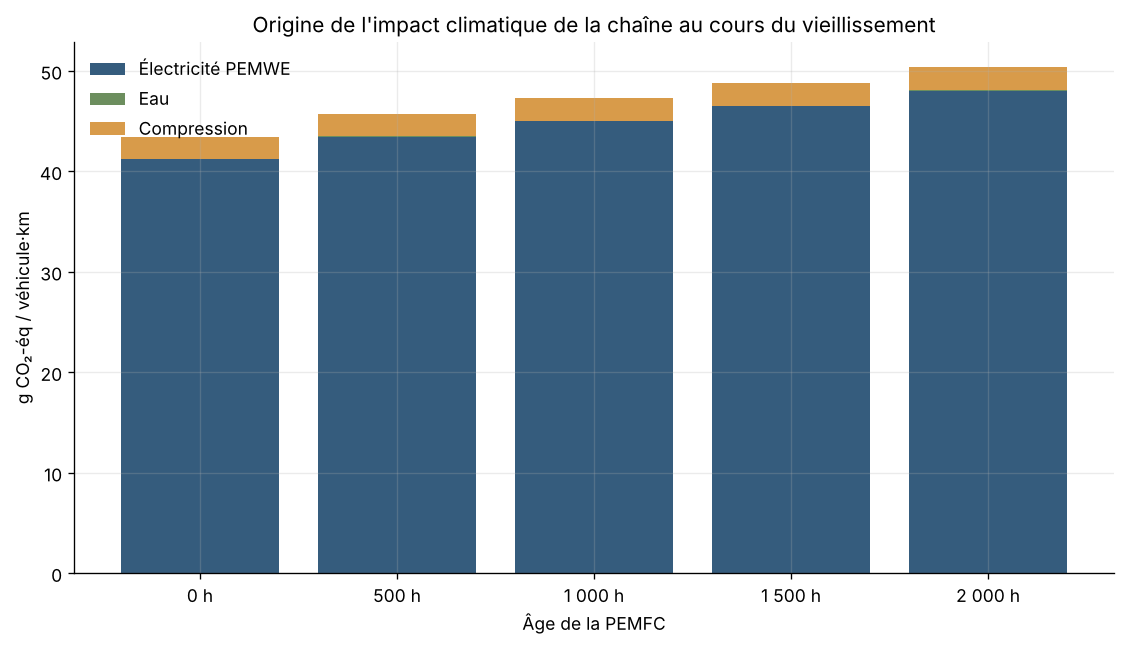

,Électricité PEMWE,Eau,Compression
0 h,41.2261,0.0456,2.1506
500 h,43.4661,0.0466,2.1972
1 000 h,44.9994,0.0474,2.2320
1 500 h,46.5026,0.0480,2.2637
2 000 h,48.0102,0.0487,2.2942


In [20]:
# Figure E : décomposition de l'impact climatique de la chaîne à l'état central.
# La fabrication n'est pas incluse ici : seules l'électricité du PEMWE, l'eau et la compression sont décomposées.
def chain_climate_components(age_fc, hwe_an=6000, pfc=FC_CENTRAL, pwe=WE_CENTRAL):
    sf=fc_state(age_fc,pfc);age_we=age_fc/HFC_AN*hwe_an;sw=we_state(age_we,pwe)
    h2km=sf["H2"]/DIST
    return {"Électricité PEMWE":h2km*float(sw["SEC"])*FE[GWP],
            "Eau":h2km*EAU[GWP],"Compression":h2km*COMP3[GWP]*E_COMP/3}

ages_plot=[0,500,1000,1500,2000]
components=pd.DataFrame([chain_climate_components(a) for a in ages_plot],index=[f"{a:,.0f} h".replace(","," ") for a in ages_plot])
fig,ax=plt.subplots(figsize=(9.5,5.5));bottom=np.zeros(len(components))
colors={"Électricité PEMWE":"#355C7D","Eau":"#6C8E5E","Compression":"#D89B4A"}
for col in components:
    vals=1000*components[col].to_numpy();ax.bar(components.index,vals,bottom=bottom,label=col,color=colors[col]);bottom+=vals
ax.set(ylabel="g CO₂-éq / véhicule·km",xlabel="Âge de la PEMFC",title="Origine de l'impact climatique de la chaîne au cours du vieillissement")
ax.legend(frameon=False);ax.grid(axis="y",alpha=.25);fig.tight_layout()
fig.savefig(OUT/"ACV_SENS_05_contributions_climat.png",dpi=240,bbox_inches="tight");plt.show();display((1000*components).round(4))


### Lecture de la décomposition

La hauteur totale correspond à l'impact climatique par véhicule-kilomètre. L'augmentation avec l'âge provient simultanément de la hausse de la consommation d'hydrogène de la PEMFC et de la hausse de la SEC du PEMWE. La décomposition indique ensuite quelle opération amont porte cette augmentation. Les impacts de fabrication ne figurent pas dans ce graphique.


## 12. Monte-Carlo du couplage

Tous les paramètres varient simultanément. Le résultat principal est l'impact climatique par véhicule·km à l'horizon commun. Les heures annuelles du PEMWE ne représentent pas une flotte : elles décrivent son taux d'utilisation.


,Analyse,Sortie,P5,Médiane,P95
0,Couplage,Impact_GWP_g_km,44.7208,51.5057,58.4133
1,Couplage,H2_kg_100km,1.0125,1.0297,1.0502
2,Couplage,SEC_kWh_kg,57.4738,58.6173,59.9758


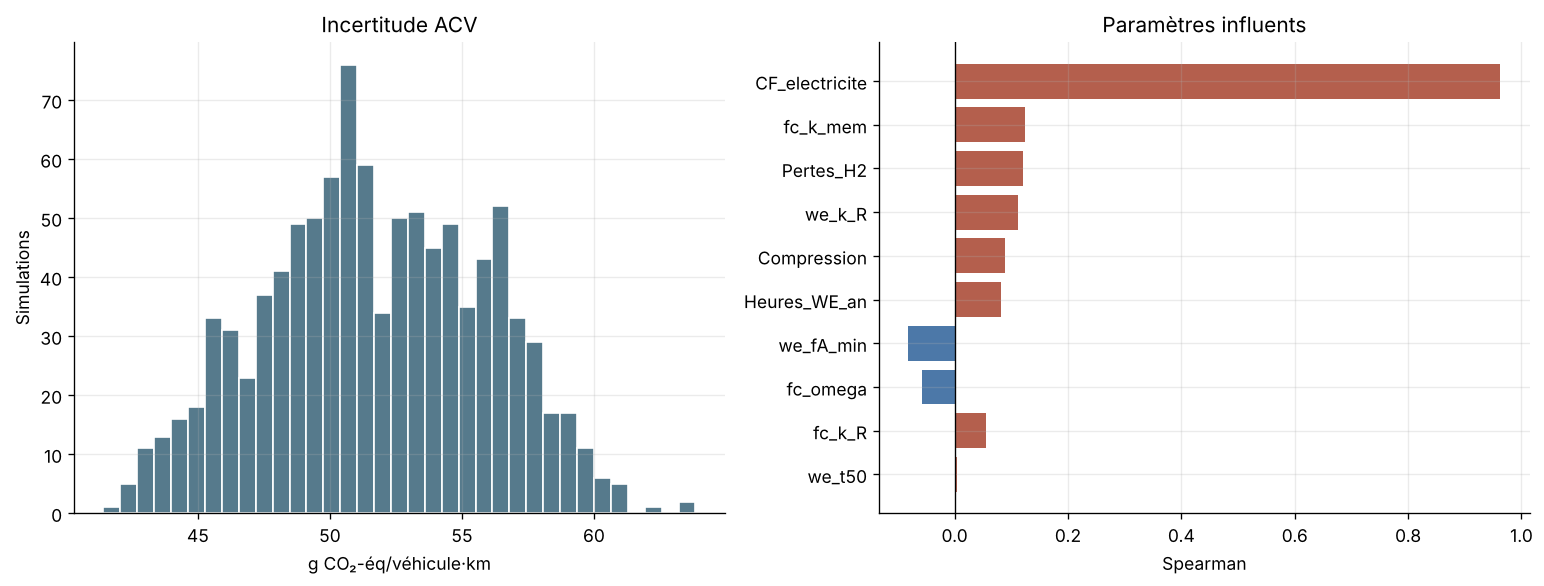

In [21]:
rng=np.random.default_rng(44)
cin=pd.DataFrame({"fc_omega":rng.uniform(*FC_BOUNDS["omega"],N_MC),"fc_k_R":rng.uniform(*FC_BOUNDS["k_R"],N_MC),
"fc_k_mem":rng.uniform(*FC_BOUNDS["k_mem"],N_MC),
"we_k_R":rng.uniform(PADGETT["dHFR"],PADGETT["dHFR"]+PADGETT["dCLR"],N_MC)/WE_R0,
"we_fA_min":rng.uniform(PADGETT["fA_masse"],PADGETT["fA_capa"],N_MC),
"we_t50":rng.uniform(CHANDESRIS_T50["couple"],CHANDESRIS_T50["lineaire"],N_MC),
"Heures_WE_an":rng.triangular(4000,6000,8000,N_MC),"Pertes_H2":rng.triangular(0,.01,.05,N_MC),
"Compression":rng.triangular(2,3,5,N_MC),"CF_electricite":rng.triangular(.8,1,1.2,N_MC)})
cout=[]
for _,r0 in cin.iterrows():
 pf=FC_CENTRAL.copy();pw=WE_CENTRAL.copy();pf.update({"omega":r0.fc_omega,"k_R":r0.fc_k_R,"k_mem":r0.fc_k_mem});pw.update({"k_R":r0.we_k_R,"fA_min":r0.we_fA_min,"t50_mem":r0.we_t50})
 sf,tw,sw,ik=coupled_endpoint(pf,pw,r0.Heures_WE_an,r0.Pertes_H2,r0.Compression,r0.CF_electricite)
 cout.append({"Impact_GWP_g_km":1000*ik[GWP],"H2_kg_100km":100*sf["H2"]/DIST,"SEC_kWh_kg":float(sw["SEC"]),"Age_WE_h":tw})
cmc=pd.concat([cin,pd.DataFrame(cout)],axis=1);cmc_sum=percentiles(cmc,["Impact_GWP_g_km","H2_kg_100km","SEC_kWh_kg"],"Couplage");display(cmc_sum.round(4))
crho=pd.DataFrame([{"Entrée":x,"Rho":spearmanr(cmc[x],cmc.Impact_GWP_g_km).statistic} for x in cin]).sort_values("Rho",key=abs)
fig,axs=plt.subplots(1,2,figsize=(13,5));axs[0].hist(cmc.Impact_GWP_g_km,bins=35,color="#567A8C",edgecolor="white")
axs[1].barh(crho.Entrée,crho.Rho,color=np.where(crho.Rho>=0,"#B45F4D","#4C78A8"));axs[1].axvline(0,color="black",lw=.8)
axs[0].set(xlabel="g CO₂-éq/véhicule·km",ylabel="Simulations",title="Incertitude ACV");axs[1].set(xlabel="Spearman",title="Paramètres influents")
fig.tight_layout();fig.savefig(OUT/"COUPLAGE_03_MonteCarlo.png",dpi=220);plt.show()

## 12.1 Figures complémentaires d’incertitude ACV

L'analyse locale précédente modifie un paramètre à la fois. Le Monte-Carlo fait varier simultanément toutes les entrées incertaines. Les figures suivantes montrent l'intervalle de résultats, les corrélations et les interactions visuelles entre hypothèses.


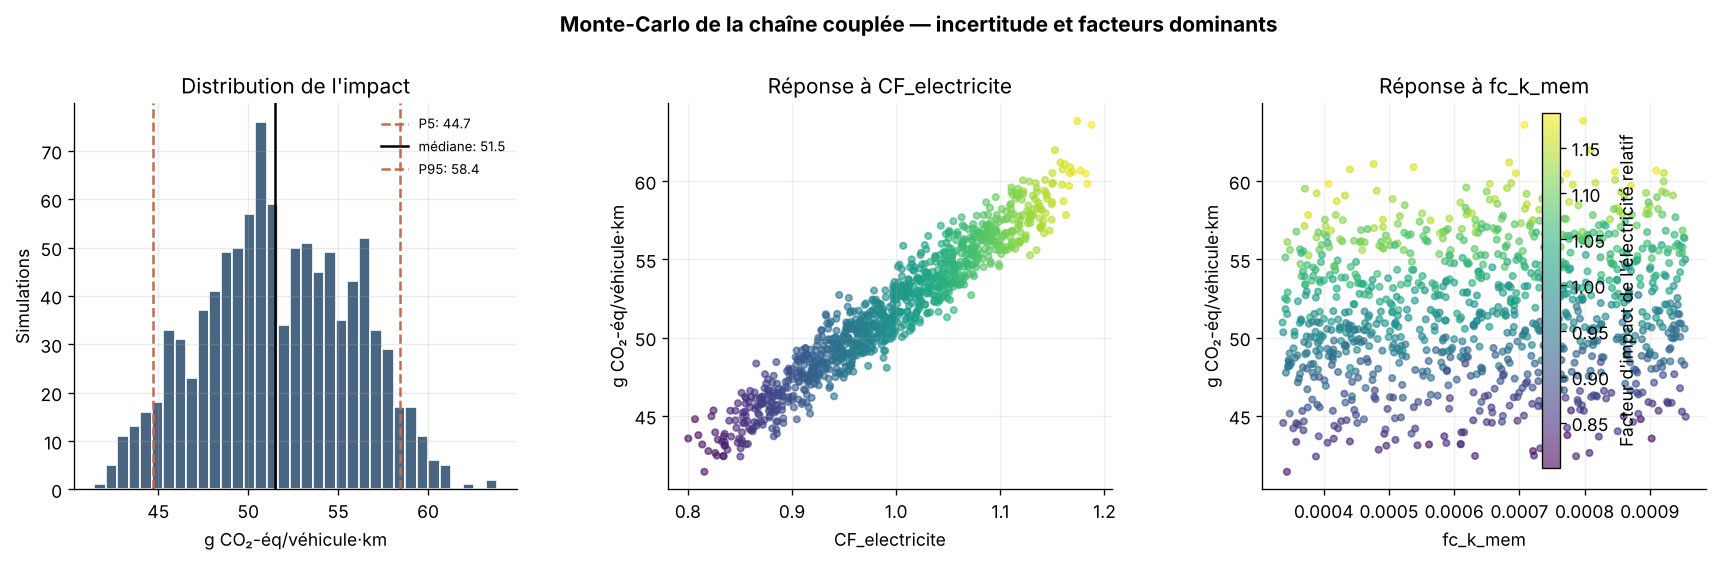

In [22]:
# Figure F : distribution, intervalle 5–95 % et nuage des deux principaux facteurs.
top2=crho.reindex(crho.Rho.abs().sort_values(ascending=False).index).Entrée.iloc[:2].tolist()
q05,q50,q95=np.percentile(cmc.Impact_GWP_g_km,[5,50,95])
fig,axs=plt.subplots(1,3,figsize=(16,4.8))
axs[0].hist(cmc.Impact_GWP_g_km,bins=35,color="#486581",edgecolor="white")
for x,ls,lab in [(q05,"--","P5"),(q50,"-","médiane"),(q95,"--","P95")]:axs[0].axvline(x,color="#C06C54" if lab!="médiane" else "black",ls=ls,lw=1.5,label=f"{lab}: {x:.1f}")
axs[0].set(xlabel="g CO₂-éq/véhicule·km",ylabel="Simulations",title="Distribution de l'impact");axs[0].legend(frameon=False,fontsize=8)
for ax,var in zip(axs[1:],top2):
    sc=ax.scatter(cmc[var],cmc.Impact_GWP_g_km,c=cmc.CF_electricite,cmap="viridis",s=15,alpha=.6)
    ax.set(xlabel=var,ylabel="g CO₂-éq/véhicule·km",title=f"Réponse à {var}");ax.grid(alpha=.2)
fig.colorbar(sc,ax=axs[1:],label="Facteur d'impact de l'électricité relatif",shrink=.8)
fig.suptitle("Monte-Carlo de la chaîne couplée — incertitude et facteurs dominants",fontweight="bold")
fig.subplots_adjust(left=.06,right=.91,bottom=.15,top=.82,wspace=.34)
fig.savefig(OUT/"ACV_SENS_06_MonteCarlo_detail.png",dpi=240,bbox_inches="tight");plt.show()


### Lecture de l'incertitude

L'histogramme donne la dispersion globale de l'impact lorsque toutes les entrées varient ensemble. Les percentiles P5 et P95 encadrent 90 % des simulations. Les nuages de points montrent la relation entre l'impact et les deux entrées les mieux corrélées ; la couleur rappelle l'influence du facteur d'impact de l'électricité.


## 13. Export, contrôles et limites scientifiques

### Ce que l'étude permet d'affirmer

- quels mécanismes contrôlent les performances dans le domaine testé ;
- l'effet du vieillissement sur H₂, SEC et impacts EF 3.1 ;
- la robustesse des conclusions aux hypothèses retenues.

### Ce qu'elle ne permet pas d'affirmer

- que les distributions choisies sont des distributions statistiques mesurées ;
- que les constantes publiées, obtenues sur d'autres cellules et protocoles, s'appliquent exactement aux stacks étudiés ;
- que l'EoL calculée est une garantie constructeur ;
- que les impacts de fabrication ou des remplacements sont inclus.

Les analyses sont conditionnelles aux profils WLTP et PEMWE disponibles, aux températures constantes et aux facteurs ACV fournis.


In [23]:
checks={"H2 initial PEMFC":np.isclose(fc_state(0,FC_CENTRAL)["H2"],.196),"SEC initiale PEMWE":np.isclose(WE_SEC0,53.675644812508565),
"Monte-Carlo PEMFC fini":np.isfinite(fc_mc[["EoL_h","H2_2000h"]]).all().all(),"Monte-Carlo PEMWE fini":np.isfinite(we_mc[["EoL_h","SEC_15000h"]]).all().all(),
"Monte-Carlo couplage fini":np.isfinite(cmc.Impact_GWP_g_km).all(),"Inventaires positifs":bool((impactkg(WE_SEC0)>0).all())}
checks.update({"Cumul PEMFC positif":bool((acv_fc_life.Impact_cumule_vieilli>0).all()),
"Cumul PEMWE positif":bool((acv_we_life.Impact_cumule_reel>0).all()),
"Première EoL cohérente":bool(fc_stop<=EOL_FC+1e-6 and we_stop<=EOL_WE+1e-6)})
display(pd.DataFrame({"Contrôle":checks.keys(),"OK":checks.values()}));assert all(checks.values())
fc_curve.to_csv(OUT/"PEMFC_trajectoire_mecanismes.csv",index=False,encoding="utf-8-sig");fc_sens.to_csv(OUT/"PEMFC_sensibilite.csv",index=False,encoding="utf-8-sig");fc_mc.to_csv(OUT/"PEMFC_MonteCarlo.csv",index=False,encoding="utf-8-sig");fc_rho.to_csv(OUT/"PEMFC_Spearman.csv",index=False,encoding="utf-8-sig")
we_curve.to_csv(OUT/"PEMWE_trajectoire_mecanismes.csv",index=False,encoding="utf-8-sig");we_sens.to_csv(OUT/"PEMWE_sensibilite.csv",index=False,encoding="utf-8-sig");we_mc.to_csv(OUT/"PEMWE_MonteCarlo.csv",index=False,encoding="utf-8-sig");we_rho.to_csv(OUT/"PEMWE_Spearman.csv",index=False,encoding="utf-8-sig")
acv_we.to_csv(OUT/"ACV_PEMWE_seul_16_indicateurs.csv",index=False,encoding="utf-8-sig");acv_fc.to_csv(OUT/"ACV_PEMFC_seule_16_indicateurs.csv",index=False,encoding="utf-8-sig");acv_chain.to_csv(OUT/"ACV_chaine_couplee_16_indicateurs.csv",index=False,encoding="utf-8-sig");acv_cum.to_csv(OUT/"ACV_chaine_impacts_cumules_2000h.csv",index=False,encoding="utf-8-sig")
acv_fc_life.to_csv(OUT/"ACV_PEMFC_cumule_jusqua_EOL.csv",index=False,encoding="utf-8-sig");acv_we_life.to_csv(OUT/"ACV_PEMWE_cumule_jusqua_EOL.csv",index=False,encoding="utf-8-sig");acv_chain_life.to_csv(OUT/"ACV_CHAINE_cumule_jusqua_premiere_EOL.csv",index=False,encoding="utf-8-sig");summary_life.to_csv(OUT/"ACV_resume_fin_de_vie_composants.csv",index=False,encoding="utf-8-sig")
coupled_sens.to_csv(OUT/"COUPLAGE_sensibilite_16_indicateurs.csv",index=False,encoding="utf-8-sig");tornado.to_csv(OUT/"COUPLAGE_tornado.csv",index=False,encoding="utf-8-sig");cmc.to_csv(OUT/"COUPLAGE_MonteCarlo.csv",index=False,encoding="utf-8-sig");crho.to_csv(OUT/"COUPLAGE_Spearman.csv",index=False,encoding="utf-8-sig")
pd.concat([fc_mc_sum,we_mc_sum,cmc_sum]).to_csv(OUT/"RESUME_incertitudes.csv",index=False,encoding="utf-8-sig")
print("Étude complète validée. Résultats :",OUT.resolve())

fc_acv_sens.to_csv(OUT/"ACV_sensibilite_PEMFC_16_indicateurs.csv",index=False,encoding="utf-8-sig")
we_acv_sens.to_csv(OUT/"ACV_sensibilite_PEMWE_16_indicateurs.csv",index=False,encoding="utf-8-sig")
components.to_csv(OUT/"ACV_contributions_climat_couplage.csv",encoding="utf-8-sig")


,Contrôle,OK
0,H2 initial PEMFC,True
1,SEC initiale PEMWE,True
2,Monte-Carlo PEMFC fini,True
3,Monte-Carlo PEMWE fini,True
4,Monte-Carlo couplage fini,True
5,Inventaires positifs,True
6,Cumul PEMFC positif,True
7,Cumul PEMWE positif,True
8,Première EoL cohérente,True


Étude complète validée. Résultats : ./resultats_sensibilite_these
